# Fitting IRAS 07546+3928 with JNesty on the GPU

This notebook fits one real spectrum with the GPU-native side of GalSpec: JAX
models (`galspec.jax_models`) sampled by **JNesty** (`galspec.jnesty_fit`). It is
the notebook form of `fit_iras07546_jax.py`; the script is what to use in a batch
pipeline, the notebook is for looking at what happens.

## What is fitted

**4200-6800 A** of the quasar **IRAS 07546+3928** (z = 0.0953) in the rest
frame -- 56 956 pixels, from H-gamma to the [S II] doublet. All of it is fitted at
once, so the continuum and the lines are constrained by the same posterior:

| wavelength | what | model |
| --- | --- | --- |
| 4340 A | H-gamma | a narrow Gaussian + a broad MultiGauss (core + wind) |
| 4861 A | H-beta | a narrow Gaussian + a broad MultiGauss (core + wind) |
| 6563 A | H-alpha | a narrow Gaussian + a broad MultiGauss (core + wind) |
| 5876 A | He I | a narrow Gaussian + one broad Gaussian |
| 4959 / 5007 A | [O III] | narrow core + one broad wing |
| 6548 / 6584 A | [N II] | narrow, doublet ratio 2.96 (atomic physics) |
| 6716 / 6731 A | [S II] | narrow, **both peaks free** (the ratio is a density diagnostic) |
| 6300 / 6364 A | [O I] | narrow, doublet ratio 3.00 |
| 4686 A | He II | a narrow Gaussian + one broad Gaussian |
| 4363 A | [O III] | single narrow Gaussian |
| all | continuum | power law + Fe II template |

Nothing outside that window is fitted: no H-delta or higher Balmer lines, no
[Ne III] 3869 or [O II] 3727, no [Ar III] 7136 or [O II] 7325. Stopping at
H-gamma on the blue side and at [S II] on the red side means **no masks are
needed** -- the Ca II H+K absorption of the host galaxy is below 4200 A, and the
atmospheric O2 A band is beyond 6800 A. The Na D window, which used to be masked,
now stays in the fit: He I 5876 sits inside it and is modelled instead.

## How it is fitted

* **No least-squares step.** Nothing is optimised before nested sampling starts,
  so the priors cannot inherit a preliminary answer. JNesty walks the prior
  directly.
* **No instrumental smoothing.** At 0.046 A per pixel the spectrum grossly
  oversamples the spectrograph: R = 2000 means ~150 km/s of instrument, while the
  narrow lines here are ~700 km/s. So the model is *not* convolved, exactly as in
  `wrk_sagan_iras07546.ipynb`; the fitted narrow width is the observed one.
* **Wide priors, taken from the data.** Line peaks from invisible to 3x the
  brightest pixel (log-uniform); the broad core 300-8000 km/s and the wind
  800-25000 km/s; the wind's amplitude anywhere between 0 and 1 of the core.
  Section 4 shows the prior spread against the data.
* **Physical ties.** Every narrow line shares one velocity shift and one width
  (measured from [O III]); the broad core and the wind are each shared across the
  three Balmer lines and He I; and the Fe II template is broadened by broad
  H-alpha itself. 30 free numbers therefore describe seventeen models.

Runtime: 10-20 minutes on one GPU with `nlive=400, dlogz=0.01` (fewer pixels and
fewer parameters than the previous 3680-7500 A version, so it is quicker). For a
quick look set `NLIVE = 200` and `DLOGZ = 0.1` in the settings cell and expect
wider error bars.


## 1. Imports and settings

Everything a user might want to change is in the next cell: the redshift, the
extinction, the wavelength window, and the two sampler settings.


In [1]:
import sys
import time
import warnings
from pathlib import Path

# The repository is used straight from a checkout (it is not installed), so put
# its root on the path: this notebook lives in <repo>/example/.
REPO = Path.cwd()
if not (REPO / "galspec").is_dir():
    REPO = REPO.parent
sys.path.insert(0, str(REPO))

import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import median_filter

import jax
import jax.numpy as jnp

import galspec
from galspec import jax_models as jxm
from galspec.jnesty_fit import JNesty_Fit, jax_devices_summary
from galspec.jnesty_fit_io import save_jnesty_fit_to_fits, load_jnesty_fit_from_fits
from galspec.utils import line_wave_dict as LINE_WAVE

warnings.simplefilter("ignore")
%matplotlib inline


In [2]:
# ---- how the fit is set up -------------------------------------------------
EXAMPLE_DIR = Path.cwd()
if not (EXAMPLE_DIR / "data" / "ir07546sed.fits").exists():
    EXAMPLE_DIR = REPO / "example"          # run from somewhere else
DATA_FILE = EXAMPLE_DIR / "data" / "ir07546sed.fits"

REDSHIFT = 0.0953          # NASA/IPAC value for IRAS 07546+3928
E_BV = 0.176               # Galactic extinction towards it (Schlafly & Finkbeiner)
WAVE_MIN, WAVE_MAX = 4200.0, 6800.0   # rest frame: H-gamma out to [S II] 6731

ERROR_FRACTION = 0.005     # floor on the pixel-to-pixel noise
PHOTON_FRACTION = 0.05     # 5% of the flux: photon noise of the source itself
# Nothing is masked any more: the blue end starts at H-gamma (so no Ca II H+K from
# the host), He I 5876 is fitted instead of masking Na D, and the red end stops
# before the atmospheric O2 A band.  The list stays because plot_fit takes one.
MASK_WINDOWS = []

NLIVE = 400                # live points the sampler keeps
DLOGZ = 0.01               # stop when < 1% of the evidence may remain unseen

BALMER_NAMES = ("Halpha", "Hbeta", "Hgamma")
TWO_COMPONENT_LINES = ("HeI",)      # narrow core + one broad component
SINGLE_LINES = ("HeII", "OIII4363")


## 2. The data

The FITS file that ships with GalSpec has flux only, no uncertainty, so the
uncertainty is measured from the data: subtract a running median, take the median
absolute deviation in a 30 A window (which ignores the few pixels belonging to
emission lines), convert to a Gaussian sigma, and smooth. That gives a
wavelength-dependent noise level, shown in the lower panel below, which rises
from ~0.3% of the flux at 4700 A to ~4% at the red end.

On top of that, **5% of the flux itself** is added in quadrature. This is the
photon noise of the source: the counts scale with the flux, so the uncertainty
does, and on the bright continuum it dominates everything else. It also covers
what the model does not describe exactly (flux calibration, the shape of the Fe
II template, departures from a pure power law), which is why 5% is the honest
number for a template fit rather than a fudge factor.

**No window is masked.** The three masks an earlier version needed are gone with
the wavelength cut: the host galaxy's Ca II H+K absorption is below 4200 A, the
Na D window is kept because He I 5876 inside it is now fitted as a line, and the
atmospheric O2 A band is beyond 6800 A.

Units: fluxes in `1e-14 erg/s/cm2/A`, velocities in km/s.


In [3]:
from astropy.io import fits
from extinction import ccm89, remove


def estimate_error(flux, window=751):
    """Per-pixel uncertainty measured from the spectrum itself.

    Subtract a running median (about 30 A), take the median of the absolute
    remainder in the same window -- which ignores the few pixels that belong to
    emission lines -- divide by 0.6745 to turn it into a Gaussian sigma, and
    smooth over a few hundred A.  A term of 5% of the flux is then added in
    quadrature: that is the photon noise of the source, which scales with the
    flux and dominates on the bright continuum.  It also stands for flux
    calibration and the shape of the Fe II template.
    """
    baseline = median_filter(flux, size=window, mode="nearest")
    scatter = median_filter(np.abs(flux - baseline), size=window, mode="nearest") / 0.6745
    scatter = median_filter(scatter, size=4 * window + 1, mode="nearest")
    statistical = np.maximum(scatter, ERROR_FRACTION * np.abs(flux))
    return np.hypot(statistical, PHOTON_FRACTION * np.abs(flux))


def mask_regions(wave, error):
    """Down-weight the windows the model does not describe."""
    error = error.copy()
    for lo, hi in MASK_WINDOWS:
        error[(wave > lo) & (wave < hi)] *= 3.0
    return error


def load_spectrum():
    """Dereddened, rest-frame spectrum between WAVE_MIN and WAVE_MAX."""
    with fits.open(DATA_FILE) as hdul:
        header = hdul[0].header
        flux_array = np.asarray(hdul[0].data, dtype=float) * 1e14
    wave_array = header["CRVAL1"] + header["CD1_1"] * np.arange(flux_array.size)

    flux_array = remove(ccm89(wave_array, E_BV, r_v=3.1, unit="aa"), flux_array)  # Milky Way
    wave_array = wave_array / (1.0 + REDSHIFT)                      # observed -> rest frame

    use = (wave_array > WAVE_MIN) & (wave_array < WAVE_MAX)
    wave_array, flux_array = wave_array[use], flux_array[use]
    return wave_array, flux_array, mask_regions(wave_array, estimate_error(flux_array))


wave, flux, error = load_spectrum()
print(f"{wave.size:,} pixels, {wave[0]:.0f}-{wave[-1]:.0f} A rest frame, "
      f"{np.median(np.diff(wave)):.4f} A per pixel")
print(f"peak flux {flux.max():.2f}, line-free level {np.percentile(flux, 15):.2f}  "
      "[1e-14 erg/s/cm2/A]")
for lo, hi in ((4200, 4600), (4600, 5400), (5400, 6000), (6000, 6800)):
    sel = (wave > lo) & (wave < hi)
    print(f"  {lo}-{hi} A: median flux {np.median(flux[sel]):5.2f}, "
          f"median error {np.median(error[sel]):5.3f} "
          f"({100*np.median(error[sel]/flux[sel]):4.1f}% of the flux)")


56,956 pixels, 4200-6800 A rest frame, 0.0456 A per pixel
peak flux 4.33, line-free level 0.50  [1e-14 erg/s/cm2/A]
  4200-4600 A: median flux  0.82, median error 0.042 ( 5.1% of the flux)
  4600-5400 A: median flux  0.70, median error 0.036 ( 5.1% of the flux)
  5400-6000 A: median flux  0.52, median error 0.027 ( 5.2% of the flux)
  6000-6800 A: median flux  0.51, median error 0.027 ( 5.2% of the flux)


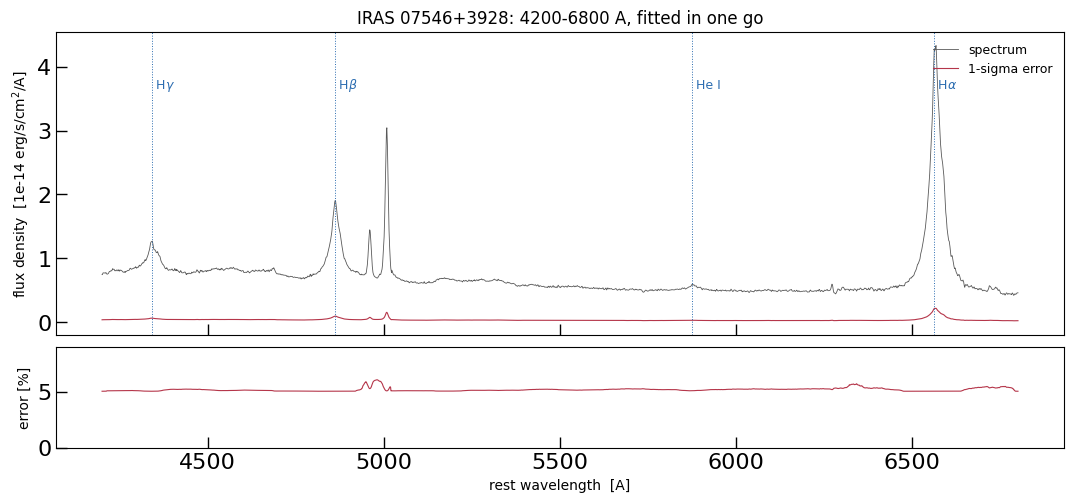

In [4]:
fig, axs = plt.subplots(2, 1, figsize=(13.0, 5.4), sharex=True,
                        gridspec_kw={"height_ratios": [3.0, 1.0], "hspace": 0.06})
step = slice(None, None, 5)
axs[0].plot(wave[step], flux[step], color="0.35", lw=0.6, label="spectrum")
axs[0].plot(wave[step], error[step], color="#b5364a", lw=0.8, label="1-sigma error")
for (lo, hi) in MASK_WINDOWS:
    axs[0].axvspan(lo, hi, color="0.85", zorder=0)
    axs[1].axvspan(lo, hi, color="0.85", zorder=0)
top = np.percentile(flux, 99.5)
for centre, text in ((LINE_WAVE["Hgamma"], "H$\\gamma$"),
                     (LINE_WAVE["Hbeta"], "H$\\beta$"),
                     (LINE_WAVE["HeI_5876"], "He I"),
                     (LINE_WAVE["Halpha"], "H$\\alpha$")):
    axs[0].axvline(centre, color="#2b6cb0", lw=0.7, ls=":")
    axs[0].text(centre, top, " " + text, fontsize=9, color="#2b6cb0")
axs[0].set_ylabel("flux density  [1e-14 erg/s/cm$^2$/A]")
axs[0].set_title("IRAS 07546+3928: 4200-6800 A, fitted in one go")
axs[0].legend(fontsize=9, frameon=False, loc="upper right")
axs[1].plot(wave[step], 100*error[step]/np.abs(flux[step]), color="#b5364a", lw=0.8)
axs[1].set_ylabel("error [%]")
axs[1].set_xlabel("rest wavelength  [A]")
axs[1].set_ylim(0, 9)
plt.tight_layout()


## 3. The model

Sixteen models, added together:

1. a **power-law continuum** anchored at 5500 A -- this is what fixes the
   continuum level and slope from the line-free regions of the whole spectrum;
2. an **Fe II template** -- the forest of iron lines that fakes a broad bump
   blueward of H-beta and is routinely mistaken for continuum. It uses
   `IronTemplate_tied`: the template is broadened by the *same* multi-Gaussian
   kernel as broad H-alpha, tied component by component, so the iron has a single
   free parameter, its amplitude. The template is loaded through
   `galspec.iron_template.load_iron_template`, which resamples it onto a grid even
   in `ln(wavelength)` -- one channel is one velocity everywhere, so a width is one
   number -- and pads the tabulated range with zeros, so the model fades out where
   the template runs out instead of reflecting its edge flux. An earlier version fitted it with one velocity
   dispersion (`IronTemplate_new`); that is still available, and the two agree
   exactly when the kernel has one component. Tying it to the line is the more
   physical choice: the iron and the Balmer lines are emitted by the same gas, so
   they cannot have different kinematics;
3. **H-alpha, H-beta, H-gamma**, each described **twice**, as in
   `wrk_sagan_iras07546.ipynb`: `n_halpha` is a `Line_Gaussian` for the narrow
   component, and `b_halpha` is a `Line_MultiGauss` for the **broad component
   only** -- its component 0 (`amp_c`, `dv_c`, `sigma_c`) is the broad core, not a
   narrow line, and `amp_w0`/`dv_w0`/`sigma_w0` add the broader wind. The wind
   amplitude is a *ratio to the core amplitude*, which is how the GalSpec models
   are written. The two models are simply added; neither knows about the other;
4. **He I 5876**, a narrow Gaussian (`n_hei`) plus **one** broad component
   (`b_hei`). It is what used to be inside the Na D mask, and it has to be
   modelled now that the mask is gone;
5. **He II 4686**, the same pattern: a narrow Gaussian (`HeII`) plus **one**
   broad Gaussian (`b_heii`). Broad He II is a standard feature of a narrow-line
   Seyfert 1 and it sits on the blue side of H-beta, where the iron and the
   Balmer wing overlap;
6. **[O III] 4959/5007** as a doublet with a narrow core and one broad wing;
7. **[N II], [S II], [O I]** doublets, plus a single narrow Gaussian for
   **[O III] 4363**.

The ties are what make this affordable:

* one `dv` and one `sigma` for **all** narrow lines, taken from the [O III] core
  (forbidden lines come from the same low-density gas);
* `dv_c`/`sigma_c` (the broad core) and `dv_w0`/`sigma_w0` (the wind) shared by the
  three broad Balmers, by He I and by He II: the two broad components are separate physical
  structures, so they get separate kinematics, but each is common to the lines.
  The Fe II kernel's two components are tied to these outright -- shifts, widths
  and the wind ratio alike;
* doublet ratios fixed by atomic physics for [O III] (2.98), [N II] (2.96) and
  [O I] (3.00) -- but **not** for [S II], whose 6716/6731 ratio is a density
  diagnostic and therefore stays free.

Note there is no `* multi` polynomial here: the reference notebook multiplies one
in because it uses a least-squares fitter with no error model, whereas here the 5%
flux term already absorbs flux-calibration error, and a high-order polynomial on
top of a power law plus an Fe II template would be strongly degenerate with both.


In [5]:
class _TieFrom:
    """Copy one parameter of another submodel (the plain-Gaussian case)."""

    def __init__(self, submodel, parameter):
        self.submodel = submodel
        self.parameter = parameter

    def __call__(self, model):
        return getattr(model[self.submodel], self.parameter)


def _tie_fn(backend, name):
    """``tie`` helpers of either backend (``jxm.tie.*`` or ``galspec.*``)."""
    return getattr(getattr(backend, "tie", backend), name)


def _power_law(backend):
    """The power-law class of either backend."""
    if backend is jxm:
        return jxm.PowerLaw1D
    from astropy.modeling import models as astro_models
    return astro_models.PowerLaw1D


def free_qualified_names(model):
    """``Submodel.parameter`` spelling of every free parameter."""
    pairs = zip(model.param_names, model.qualified_param_names)
    free = set(model.free_param_names)
    return [q for flat, q in pairs if flat in free]


In [6]:
def build_model(backend=jxm, include_iron=None):
    """The full model: two models per line, narrow and broad.

    Every Balmer line (and He I 5876) is described twice, as in
    ``wrk_sagan_iras07546.ipynb``:

    ``n_<line>``  a ``Line_Gaussian`` for the narrow component, tied to the
                  [O III] core, so all the narrow lines share one kinematics;
    ``b_<line>``  a ``Line_MultiGauss`` for the broad component only.  Component 0
                  is the broad core -- "core" names component 0, it is not a
                  narrow line -- and ``amp_w0``/``dv_w0``/``sigma_w0`` add the
                  broader wind.

    ``backend`` is ``galspec.jax_models`` (what the fit uses) or ``galspec``
    itself (the astropy twin used for plotting).  No convolution is applied: see
    the introduction.
    """
    if include_iron is None:
        # the astropy twin used for plotting gets the iron as a curve instead
        include_iron = backend is jxm

    # -- continuum: a power law anchored at 5500 A, plus the iron pseudo-continuum --
    continuum = _power_law(backend)(amplitude=0.55, x_0=5500.0, alpha=1.0,
                                    fixed={"x_0": True}, name="Continuum")
    # The iron: an older version of this notebook fitted it with one velocity
    # dispersion and one shift,
    #
    #     iron = backend.IronTemplate_new(amplitude=0.2, sigma=2500.0, z=0.0,
    #                                     dv=0.0, name="FeII")
    #
    # and those two lines are kept here as the reference the tied model was checked
    # against.  What the fit uses is the *tied* template, broadened by the profile of
    # broad H-alpha.  Its parameters carry the same names as the Line_MultiGauss they
    # come from (n_components=2 is a core plus one wind) and there are no weights of
    # their own: a Line_MultiGauss already is a weighted sum, the convolution
    # renormalises it, so the core amplitude cancels and the wind ratio -- the line's
    # own amp_w0 -- is the only weight left.  One free parameter: the amplitude.
    iron = None
    if include_iron:
        iron = backend.IronTemplate_tied(n_components=2, amplitude=0.2, z=0.0,
                                         dv_c=0.0, sigma_c=1500.0,
                                         amp_w0=0.10, dv_w0=0.0, sigma_w0=6000.0,
                                         name="FeII")
        iron.z.fixed = True

    # -- narrow components: one Gaussian per line, one kinematics for all -------
    def narrow(name, wavec, amplitude, model_name):
        return backend.Line_Gaussian(amplitude=amplitude, dv=0.0, sigma=700.0,
                                     wavec=wavec, name=model_name)

    # -- broad components: a Line_MultiGauss whose component 0 is the broad core --
    n_halpha = narrow("Halpha", LINE_WAVE["Halpha"], 2.2, "n_halpha")
    n_hbeta = narrow("Hbeta", LINE_WAVE["Hbeta"], 0.8, "n_hbeta")
    n_hgamma = narrow("Hgamma", LINE_WAVE["Hgamma"], 0.4, "n_hgamma")
    n_hei = narrow("HeI", LINE_WAVE["HeI_5876"], 0.12, "n_hei")

    b_halpha = backend.Line_MultiGauss(
        n_components=2, amp_c=0.65, dv_c=0.0, sigma_c=1500.0,
        wavec=LINE_WAVE["Halpha"], name="b_halpha",
        amp_w0=0.10, dv_w0=0.0, sigma_w0=6000.0)
    b_hbeta = backend.Line_MultiGauss(
        n_components=2, amp_c=0.22, dv_c=0.0, sigma_c=1500.0,
        wavec=LINE_WAVE["Hbeta"], name="b_hbeta",
        amp_w0=0.20, dv_w0=0.0, sigma_w0=6000.0)
    b_hgamma = backend.Line_MultiGauss(
        n_components=2, amp_c=0.10, dv_c=0.0, sigma_c=1500.0,
        wavec=LINE_WAVE["Hgamma"], name="b_hgamma",
        amp_w0=0.20, dv_w0=0.0, sigma_w0=6000.0)
    # He I 5876: one broad component is enough.  It sits where the Na D mask used to
    # be: with the mask gone, the line has to be modelled rather than hidden.
    b_hei = backend.Line_MultiGauss(
        n_components=1, amp_c=0.06, dv_c=0.0, sigma_c=1500.0,
        wavec=LINE_WAVE["HeI_5876"], name="b_hei")
    # He II 4686 gets a broad component too: in a narrow-line Seyfert 1 the broad
    # He II is strong enough to measure, and one Gaussian is enough.  It shares the
    # broad-core kinematics, so it costs one number: its peak.
    b_heii = backend.Line_MultiGauss(
        n_components=1, amp_c=0.05, dv_c=0.0, sigma_c=1500.0,
        wavec=LINE_WAVE["HeII_4686"], name="b_heii")

    # -- forbidden lines -------------------------------------------------------
    o3 = backend.Line_MultiGauss_doublet(
        n_components=2, amp_c0=1.8, amp_c1=1.8 / 2.98, dv_c=0.0, sigma_c=700.0,
        wavec0=LINE_WAVE["OIII_5007"], wavec1=LINE_WAVE["OIII_4959"],
        name="OIII", amp_w0=0.3, dv_w0=0.0, sigma_w0=1800.0)
    n2 = backend.Line_MultiGauss_doublet(
        n_components=1, amp_c0=1.0, amp_c1=1.0 / 2.96, dv_c=0.0, sigma_c=700.0,
        wavec0=LINE_WAVE["NII_6583"], wavec1=LINE_WAVE["NII_6548"], name="NII")
    # [S II]: the two peaks stay independent -- their ratio is a density
    # diagnostic, so it has to come out of the fit rather than go in as a guess.
    s2 = backend.Line_MultiGauss_doublet(
        n_components=1, amp_c0=0.10, amp_c1=0.10, dv_c=0.0, sigma_c=700.0,
        wavec0=LINE_WAVE["SII_6716"], wavec1=LINE_WAVE["SII_6731"], name="SII")
    o1 = backend.Line_MultiGauss_doublet(
        n_components=1, amp_c0=0.05, amp_c1=0.05 / 3.0, dv_c=0.0, sigma_c=700.0,
        wavec0=LINE_WAVE["OI_6300"], wavec1=LINE_WAVE["OI_6364"], name="OI")

    # -- other single narrow Gaussians ----------------------------------------
    he2 = narrow("HeII", LINE_WAVE["HeII_4686"], 0.08, "HeII")   # the narrow one
    o3_4363 = narrow("OIII4363", LINE_WAVE["OIII_4363"], 0.05, "OIII4363")

    # Nothing blueward of H-gamma or redward of [S II] is modelled: the data are
    # 4200-6800 A.  Gone with the old range: H-delta, H-epsilon, H8-H11,
    # [Ne III] 3869, [O II] 3727, [Ar III] 7136, [O II] 7325.
    components = [continuum]
    if iron is not None:
        components.append(iron)
    components += [n_halpha, b_halpha, n_hbeta, b_hbeta, n_hgamma, b_hgamma,
                   o3, n2, s2, o1, he2, b_heii, o3_4363, n_hei, b_hei]
    model = components[0]
    for _component in components[1:]:
        model = model + _component

    # -- ties: one narrow kinematics for every narrow line, [O III] as reference --
    for line in (n_halpha, n_hbeta, n_hgamma, n_hei):
        line.dv.tied = _TieFrom("OIII", "dv_c")
        line.sigma.tied = _TieFrom("OIII", "sigma_c")
    for line in (n2, s2, o1):
        line.dv_c.tied = _tie_fn(backend, "tie_MultiGauss_dv_c")("OIII")
        line.sigma_c.tied = _tie_fn(backend, "tie_MultiGauss_sigma_c")("OIII")
    for line in (he2, o3_4363):
        line.dv.tied = _TieFrom("OIII", "dv_c")
        line.sigma.tied = _TieFrom("OIII", "sigma_c")

    # -- ties: one broad kinematics, set by broad H-alpha ----------------------
    # The broad core and the wind are separate structures, so they get separate
    # kinematics; what is shared is the shape.  Each line keeps its own peak and its
    # own wind ratio, which is how the Balmer decrement falls out of the fit.
    for line in (b_hbeta, b_hgamma):
        line.dv_c.tied = _tie_fn(backend, "tie_MultiGauss_dv_c")("b_halpha")
        line.sigma_c.tied = _tie_fn(backend, "tie_MultiGauss_sigma_c")("b_halpha")
        line.dv_w0.tied = _tie_fn(backend, "tie_MultiGauss_dv_w0")("b_halpha")
        line.sigma_w0.tied = _tie_fn(backend, "tie_MultiGauss_sigma_w0")("b_halpha")
    for line in (b_hei, b_heii):
        line.dv_c.tied = _tie_fn(backend, "tie_MultiGauss_dv_c")("b_halpha")
        line.sigma_c.tied = _tie_fn(backend, "tie_MultiGauss_sigma_c")("b_halpha")
    o3.dv_w0.tied = _TieFrom("OIII", "dv_c")   # the wing sits at the core velocity

    # -- ties: the iron kernel IS broad H-alpha -------------------------------
    # Kernel component for kernel component: the core takes the core's shift and
    # width, the wind takes the wind's, ratios included.  Nothing is left to the iron
    # but its amplitude.  The compound above already exists, which is what lets these
    # tie references resolve.
    if iron is not None:
        iron.dv_c.tied = _tie_fn(backend, "tie_MultiGauss_dv_c")("b_halpha")
        iron.sigma_c.tied = _tie_fn(backend, "tie_MultiGauss_sigma_c")("b_halpha")
        iron.amp_w0.tied = _tie_fn(backend, "tie_MultiGauss_amp_w0")("b_halpha")
        iron.dv_w0.tied = _tie_fn(backend, "tie_MultiGauss_dv_w0")("b_halpha")
        iron.sigma_w0.tied = _tie_fn(backend, "tie_MultiGauss_sigma_w0")("b_halpha")

    # -- doublet ratios fixed by atomic physics --------------------------------
    # (not [S II]: its ratio is density-sensitive and stays a free parameter)
    o3.amp_c1.tied = _tie_fn(backend, "tie_MultiGauss_doublet_ratio")("OIII", 2.98)
    n2.amp_c1.tied = _tie_fn(backend, "tie_MultiGauss_doublet_ratio")("NII", 2.96)
    o1.amp_c1.tied = _tie_fn(backend, "tie_MultiGauss_doublet_ratio")("OI", 3.00)

    return model


model = build_model(jxm)

# Display names for plots: one label per *model*, because the narrow Gaussian and the
# broad MultiGauss of the same line are separate objects and are drawn separately.
MODEL_LABELS = {
    "Continuum": "Continuum", "FeII": "Fe II",
    "n_halpha": r"BH$\alpha$ (narrow)", "b_halpha": r"BH$\alpha$ (broad)",
    "n_hbeta": r"BH$\beta$ (narrow)", "b_hbeta": r"BH$\beta$ (broad)",
    "n_hgamma": r"BH$\gamma$ (narrow)", "b_hgamma": r"BH$\gamma$ (broad)",
    "n_hei": r"He I (narrow)", "b_hei": r"He I (broad)",
    "b_heii": r"He II (broad)",
    "OIII": r"[O III]", "NII": r"[N II]", "SII": r"[S II]", "OI": r"[O I]",
    "OIII4363": r"[O III] 4363", "HeII": r"He II",
}
for _name in model.submodel_names:
    if _name in MODEL_LABELS:
        model[_name].label = MODEL_LABELS[_name]



In [7]:
print(f"{len(model.free_param_names)} free parameters "
      f"({len(model.qualified_param_names)} in total, the rest are fixed or tied):\n")
for q in free_qualified_names(model):
    print("   ", q)


30 free parameters (90 in total, the rest are fixed or tied):

    Continuum.amplitude
    Continuum.alpha
    FeII.amplitude
    n_halpha.amplitude
    b_halpha.amp_c
    b_halpha.dv_c
    b_halpha.sigma_c
    b_halpha.amp_w0
    b_halpha.dv_w0
    b_halpha.sigma_w0
    n_hbeta.amplitude
    b_hbeta.amp_c
    b_hbeta.amp_w0
    n_hgamma.amplitude
    b_hgamma.amp_c
    b_hgamma.amp_w0
    OIII.amp_c0
    OIII.dv_c
    OIII.sigma_c
    OIII.amp_w0
    OIII.sigma_w0
    NII.amp_c0
    SII.amp_c0
    SII.amp_c1
    OI.amp_c0
    HeII.amplitude
    b_heii.amp_c
    OIII4363.amplitude
    n_hei.amplitude
    b_hei.amp_c


### Why the iron is broadened by the line profile

That is the model the fit uses. The kernel is a multi-Gaussian whose shifts,
widths and weights are tied to the broad components of H-alpha, and the
normalisation keeps the iron scale separate from the line amplitudes. The cell
below builds the same construction standalone, compares the resulting iron
profile with the single-Gaussian one, and measures what the extra work costs.

The arithmetic is simple: subtract the template's own width in quadrature for
each component, then average the shifted profiles. It is **not free**: a
two-component kernel adds 0.1-0.45 ms per evaluation depending on how busy the
card is -- a bigger share of a small model than of a full spectrum, so the
percentage below depends on what else is in the model -- and that is up to a few
extra minutes over a whole fit. The
price is one smoothing and one interpolation per component, done on the 2 389-point
template rather than on the spectrum. Run the cell below and it measures the
number where you are.

What it *does* change is the physics: the iron gets the same velocity structure as
the Balmer lines, including any asymmetry, so it is the right model when the two
are known to share a broad-line region and the wrong one when they are not.


tied iron parameters: ('amplitude', 'z', 'dv_c', 'sigma_c', 'amp_w0', 'dv_w0', 'sigma_w0')
free after tying   : ('amplitude',)
(the core and the wind are both tied to broad H-alpha)
kernel parameters  : ('dv_c', 'sigma_c', 'amp_w0', 'dv_w0', 'sigma_w0')
tied kernel changes the iron profile by at most 10% of its peak


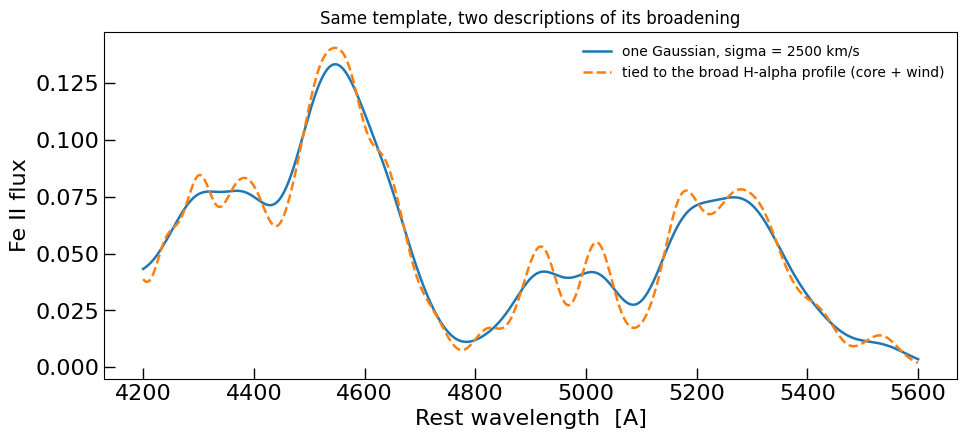

single-Gaussian iron: 0.28 ms per evaluation
tied (2 components) : 0.48 ms per evaluation
cost of the tied kernel: +0.20 ms (+72%), i.e. 0.3 min over 1e5 evaluations


In [8]:
# This is the model the fit uses, in isolation: the iron broadened by the *same*
# multi-Gaussian profile as the broad Balmer lines, tied component by component.
# The cell builds it, resolves the ties, compares the resulting iron profile with
# the single-Gaussian one, and measures what the extra work costs.
fe_tied = jxm.IronTemplate_tied(n_components=2, amplitude=0.2,
                                dv_c=0.0, sigma_c=1500.0,
                                amp_w0=0.10, dv_w0=0.0, sigma_w0=6000.0,
                                template_name="park2022", name="FeII_tied")
# a standalone copy of the broad H-alpha line (a Line_MultiGauss used for the broad
# component only), so this demonstration cannot touch the model that the fit uses
b_halpha = jxm.Line_MultiGauss(n_components=2, amp_c=0.65, sigma_c=1500.0,
                               wavec=LINE_WAVE["Halpha"], name="b_halpha",
                               amp_w0=0.10, sigma_w0=6000.0)
# compose first: a tie is resolved through the compound that holds both models
demo = b_halpha + fe_tied
fe_tied.dv_c.tied = jxm.tie.tie_MultiGauss_dv_c("b_halpha")
fe_tied.sigma_c.tied = jxm.tie.tie_MultiGauss_sigma_c("b_halpha")
fe_tied.amp_w0.tied = jxm.tie.tie_MultiGauss_amp_w0("b_halpha")
fe_tied.dv_w0.tied = jxm.tie.tie_MultiGauss_dv_w0("b_halpha")
fe_tied.sigma_w0.tied = jxm.tie.tie_MultiGauss_sigma_w0("b_halpha")

print("tied iron parameters:", fe_tied.param_names)
print("free after tying   :", fe_tied.free_param_names)
print("(the core and the wind are both tied to broad H-alpha)")
print("kernel parameters  :", fe_tied.kernel_param_names())

# iron profile: tied to the line profile versus one Gaussian of the same width
theta_demo = jnp.asarray(demo.get_free_params())       # ties resolved by the compound
theta_halpha = jnp.asarray(b_halpha.get_free_params())  # the line on its own
iron_tied = (np.asarray(demo.flux(wave, theta_demo))
             - np.asarray(b_halpha.flux(wave, theta_halpha)))
# the single-Gaussian description, for reference (the fit no longer uses it)
iron_plain = np.asarray(
    jxm.IronTemplate_new(amplitude=0.2, sigma=2500.0, dv=0.0,
                         name="FeII_plain").flux(wave, jnp.asarray([0.2, 2500.0, 0.0])))
print(f"tied kernel changes the iron profile by at most "
      f"{np.max(np.abs(iron_tied - iron_plain)) / np.max(iron_plain) * 100:.0f}% of its peak")

sel = (wave > 4200) & (wave < 5600)
fig, ax = plt.subplots(figsize=(11.0, 4.5))
ax.plot(wave[sel], iron_plain[sel], color="C0", lw=1.8,
        label="one Gaussian, sigma = 2500 km/s")
ax.plot(wave[sel], iron_tied[sel], color="C1", lw=1.8, ls="--",
        label="tied to the broad H-alpha profile (core + wind)")
ax.set_xlabel("Rest wavelength  [A]", fontsize=16)
ax.set_ylabel("Fe II flux", fontsize=16)
ax.legend(fontsize=10, frameon=False)
ax.set_title("Same template, two descriptions of its broadening", fontsize=12)
plt.show()

# What it costs.  Both compounds carry the same H-alpha line, so the difference is
# the iron cost.  Both are compiled and run once *before* timing: a GPU idles at low
# clock speed and ramps up under load, so timing the first model cold would credit
# the second one with a speed-up it does not have.
x = jnp.asarray(wave)
demo_plain = b_halpha.copy() + jxm.IronTemplate_new(amplitude=0.2, sigma=2500.0,
                                                   dv=0.0, name="FeII_plain")
evaluate_plain = jax.jit(lambda t: demo_plain.flux(x, t))
evaluate_tied = jax.jit(lambda t: demo.flux(x, t))
theta_plain = jnp.asarray(demo_plain.get_free_params())
for _ in range(3):                       # compile, then warm the clocks
    evaluate_plain(theta_plain).block_until_ready()
    evaluate_tied(theta_demo).block_until_ready()


def best_ms(evaluate, theta, reps=20, blocks=5):
    """Fastest of several blocks: the median is inflated by any stray GPU contention."""
    times = []
    for _ in range(blocks):
        start = time.perf_counter()
        for _ in range(reps):
            evaluate(theta).block_until_ready()
        times.append((time.perf_counter() - start) / reps * 1e3)
    return min(times)


# each model is measured twice, in alternating order: if the clock is still
# ramping, the two runs disagree and the faster one is the honest number
plain_first = best_ms(evaluate_plain, theta_plain)
tied_first = best_ms(evaluate_tied, theta_demo)
tied_second = best_ms(evaluate_tied, theta_demo)
plain_second = best_ms(evaluate_plain, theta_plain)
plain_ms = min(plain_first, plain_second)
tied_ms = min(tied_first, tied_second)
extra_min = (tied_ms - plain_ms) * 1e5 / 6e4        # per 1e5 evaluations
print(f"single-Gaussian iron: {plain_ms:.2f} ms per evaluation")
print(f"tied (2 components) : {tied_ms:.2f} ms per evaluation")
print(f"cost of the tied kernel: {tied_ms - plain_ms:+.2f} ms "
      f"({100 * (tied_ms - plain_ms) / plain_ms:+.0f}%), i.e. {extra_min:.1f} min "
      f"over 1e5 evaluations")


## 4. The priors -- broad, and justified by the data

This is the part that decides whether a fit is honest. Every range below comes
from the spectrum itself, never from a previous fit:

| what | range | why |
| --- | --- | --- |
| line peaks | 1e-3 to 3x the brightest pixel, **log-uniform** | four decades: from invisible to implausibly strong |
| broad/narrow ratio | 1e-3 to 8, log-uniform | from no broad component to one that dominates |
| wind/core ratio | 0-1, **uniform** | no wind is brighter than its own core -- and this is what breaks the core-wind degeneracy |
| narrow widths | 30-800 km/s | unresolved up to the widest known narrow-line region |
| broad core | 300-8000 km/s | FWHM up to ~19000 km/s |
| broad wind | 800-25000 km/s | FWHM up to ~59000 km/s, for a line wing |
| continuum level | 0.2-4x the line-free windows | cannot be negative, cannot swamp the lines |
| He I broad/narrow | 0-1, uniform | same ratio prior as the Balmers |
| iron amplitude | 1e-3 to 3x the continuum level | the only free iron parameter |
| [S II] 6716/6731 | both peaks 1e-3 to 3x peak | the ratio is measured, not assumed |

One subtlety: bounds passed in `bounds_dict` are *linear*-uniform by design, and a
linear prior over four decades would put 99% of its probability at the bright
end. Amplitudes therefore get an explicit `log_uniform` callable through
`custom_priors`, so every factor of ten is equally likely.

A second, less obvious one: the two components of a `Line_MultiGauss` are
**exchangeable**. Swapping them — `amp_c' = amp_c * amp_w0`,
`sigma_c' = sigma_w0`, `dv_c' = dv_c + dv_w0`, `amp_w0' = 1/amp_w0`,
`dv_w0' = -dv_w0`, `sigma_w0' = sigma_c` — leaves the spectrum identical to 3e-16,
and the Fe II kernel follows it because it is tied to the same profile. With
overlapping width priors the posterior is therefore bimodal and a fit reports
whichever mode it happened to fill. One number settles it: `amp_w0` is uniform on
[0, 1], so the swapped solution -- which needs `amp_w0' = 1/amp_w0 > 1` -- is
outside the prior, and the *widths* keep their full range. The fit below lands in
one mode with no posterior samples on the mirror branch;
`develop/dev_jax/io_test/iron_tied_io_test.html` measures the same thing on a
mock.


In [9]:
def log_uniform(lower, upper):
    """Prior that is uniform per decade between ``lower`` and ``upper``."""
    lo, hi = np.log10(lower), np.log10(upper)

    def transform(u):
        return 10.0 ** (lo + (hi - lo) * u)

    return transform


def make_priors(flux):
    """Bounds and log-uniform priors for the whole model.

    ``amp_w0`` -- the wind's amplitude relative to the broad core -- is uniform on
    [0, 1].  A wind is by definition no brighter than its core, and the bound is
    what breaks the core-wind degeneracy: component 0 and component 1 of a
    Line_MultiGauss are exchangeable (swapping them leaves the spectrum
    bit-identical), but the swap sends amp_w0 -> 1/amp_w0, i.e. outside [0, 1].
    The *widths* therefore keep their full data-driven range.
    See ``develop/dev_jax/io_test/iron_tied_io_test.html``.
    """
    peak = float(np.max(flux))
    continuum = float(np.percentile(flux, 15.0))
    amp = (1e-3, 3.0 * peak)      # line peaks
    ratio = (1e-3, 8.0)           # broad / narrow amplitude
    wind = (0.0, 1.0)             # wind / core: bounded, and that breaks the
                                  # core-wind exchange degeneracy (swap -> 1/amp_w0)

    bounds = {
        "Continuum.amplitude": (0.2 * continuum, 4.0 * continuum),
        "Continuum.alpha": (-5.0, 5.0),
        # one free parameter for the iron: its amplitude.  No width or shift prior
        # is needed because the kernel is broad H-alpha.
        "FeII.amplitude": (1e-3, 3.0 * continuum),
        "OIII.dv_c": (-1000.0, 1000.0),
        "OIII.sigma_c": (30.0, 800.0),
        "OIII.amp_c0": amp,
        "OIII.amp_w0": wind,
        "OIII.sigma_w0": (300.0, 4000.0),
        "NII.amp_c0": amp,
        "SII.amp_c0": amp, "SII.amp_c1": amp,
        "OI.amp_c0": amp,
        # broad H-alpha: the only place where the broad kinematics are free
        "b_halpha.dv_c": (-2500.0, 2500.0),
        "b_halpha.sigma_c": (300.0, 8000.0),
        "b_halpha.amp_w0": wind,
        "b_halpha.dv_w0": (-6000.0, 6000.0),
        "b_halpha.sigma_w0": (800.0, 25000.0),
    }
    for name in BALMER_NAMES:
        bounds[f"n_{name.lower()}.amplitude"] = amp
        bounds[f"b_{name.lower()}.amp_c"] = amp
        bounds[f"b_{name.lower()}.amp_w0"] = wind
    bounds["n_hei.amplitude"] = amp
    bounds["b_hei.amp_c"] = amp
    bounds["b_heii.amp_c"] = amp
    for name in SINGLE_LINES:
        bounds[f"{name}.amplitude"] = amp

    # peak heights get a log-uniform prior; the wind ratios are bounded by 1 and
    # take a uniform one instead
    log_params = [n for n in bounds
                  if n.endswith(("amp_c", "amp_c0", "amp_c1", "amplitude"))]
    return bounds, {n: log_uniform(*bounds[n]) for n in log_params}


bounds, custom_priors = make_priors(flux)
print(f"{len(bounds)} free parameters, each with an explicit prior:")
for q in free_qualified_names(model):
    lo, hi = bounds[q]
    kind = "log" if q in custom_priors else "linear"
    print(f"  {q:22s} ({lo:9.3f}, {hi:9.3f})  {kind}-uniform")



30 free parameters, each with an explicit prior:
  Continuum.amplitude    (    0.100,     1.997)  log-uniform
  Continuum.alpha        (   -5.000,     5.000)  linear-uniform
  FeII.amplitude         (    0.001,     1.497)  log-uniform
  n_halpha.amplitude     (    0.001,    12.997)  log-uniform
  b_halpha.amp_c         (    0.001,    12.997)  log-uniform
  b_halpha.dv_c          (-2500.000,  2500.000)  linear-uniform
  b_halpha.sigma_c       (  300.000,  8000.000)  linear-uniform
  b_halpha.amp_w0        (    0.000,     1.000)  linear-uniform
  b_halpha.dv_w0         (-6000.000,  6000.000)  linear-uniform
  b_halpha.sigma_w0      (  800.000, 25000.000)  linear-uniform
  n_hbeta.amplitude      (    0.001,    12.997)  log-uniform
  b_hbeta.amp_c          (    0.001,    12.997)  log-uniform
  b_hbeta.amp_w0         (    0.000,     1.000)  linear-uniform
  n_hgamma.amplitude     (    0.001,    12.997)  log-uniform
  b_hgamma.amp_c         (    0.001,    12.997)  log-uniform
  b_hgamma.amp_

### Does the prior cover the data?

A useful sanity check, and the reason no least-squares seed is needed: draw
parameter sets from the prior, evaluate the model for each, and look at the
spread. If the data fall inside that band, the prior contains the answer. (The
band is wide on purpose -- that is what "broad prior" means.)


In [10]:
fit = JNesty_Fit(model, wave, flux, error,
                 bounds_dict=bounds, custom_priors=custom_priors,
                 nlive=NLIVE, bound="multi", device="auto")

print(f"free parameters : {fit.ndim}")
print(f"device          : {fit.device}  [{jax_devices_summary()}]")
print(f"live points     : {fit.nlive}")


free parameters : 30
device          : gpu  [gpu:0 (19.0 GB)]
live points     : 400


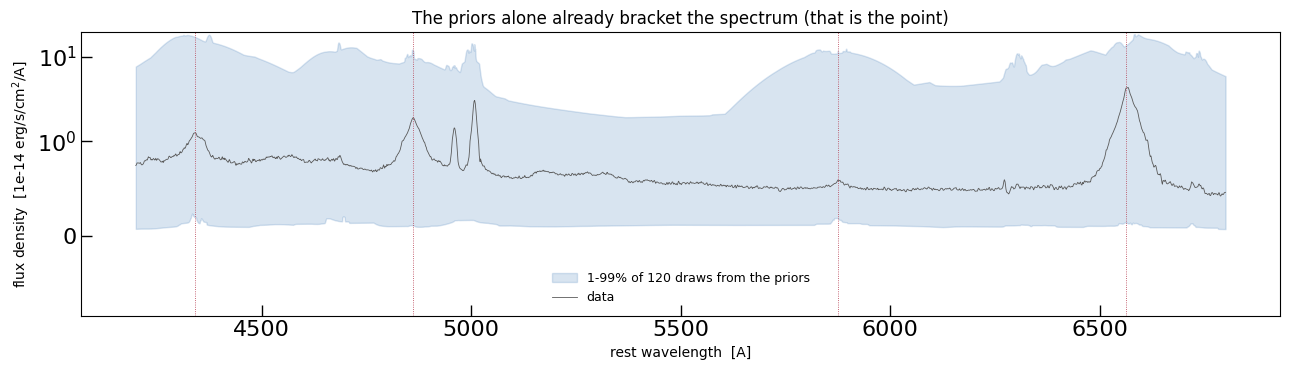

In [11]:
model.prepare(wave)
rng = np.random.default_rng(0)
u = rng.random((120, fit.ndim))
theta_prior = np.array([fit.prior_transform(row) for row in u])
draws = np.asarray(model.flux_batch(wave, theta_prior))

fig, ax = plt.subplots(figsize=(13.0, 3.8))
step = slice(None, None, 11)
ax.fill_between(wave[step], np.percentile(draws, 1, axis=0)[step],
                np.percentile(draws, 99, axis=0)[step], color="#2b6cb0",
                alpha=0.18, label="1-99% of 120 draws from the priors")
ax.plot(wave[step], flux[step], color="0.35", lw=0.6, label="data")
for centre in (LINE_WAVE["Hgamma"], LINE_WAVE["Hbeta"],
               LINE_WAVE["HeI_5876"], LINE_WAVE["Halpha"]):
    ax.axvline(centre, color="#b5364a", lw=0.6, ls=":")
ax.set_yscale("symlog", linthresh=1.0)
ax.set_xlabel("rest wavelength  [A]")
ax.set_ylabel("flux density  [1e-14 erg/s/cm$^2$/A]")
ax.set_title("The priors alone already bracket the spectrum (that is the point)")
ax.legend(fontsize=9, frameon=False)
plt.tight_layout()


## 5. Run the sampler

`JNesty_Fit` compiles the log-likelihood and the prior transform with `jax.jit`,
batches likelihood evaluations on the GPU, and runs nested sampling until the
remaining evidence is below `dlogz`.

Nested sampling keeps `NLIVE` "live points" drawn from the prior and repeatedly
replaces the worst one with a point of higher likelihood: the volume shrinks, the
likelihood rises, and the integral of both is the evidence. The surviving points
are a weighted sample of the posterior, which is what we quote below.

JNesty seeds itself internally, so reruns agree statistically: two separate runs
of the equivalent script came out identical to the second decimal in `log Z`.


In [12]:
started = time.perf_counter()
fit.fit(progress=True, dlogz=DLOGZ, max_iterations=200_000)
wall = time.perf_counter() - started

print(f"log Z          : {fit.log_evidence:.2f} +- {fit.log_evidence_err:.2f}")
print(f"iterations     : {fit.n_iterations}")
print(f"wall clock     : {wall/60:.1f} min")


JNesty:   0%|          | 0/200000 [00:00<?, ?it/s]

log Z          : 130880.55 +- 0.64
iterations     : 71065
wall clock     : 14.3 min


## 6. What the fit says

The table is the answer: posterior median and the 16th/84th percentiles (a 68%
credible interval, the Bayesian counterpart of "1 sigma").

Read it with the ties in mind -- `OIII.dv_c` is the shift of *every* narrow line,
and `b_halpha.sigma_w0` is the width of the wind in *all three* Balmer lines, in
He I and in the Fe II kernel.


In [13]:
PARAM_NOTES = {
    "Continuum.amplitude": "continuum flux density at 5500 A",
    "Continuum.alpha": "continuum slope (F_nu ~ nu^-alpha)",
    "FeII.amplitude": "iron strength (kernel tied to broad H-alpha)",
    "OIII.amp_c0": "[O III] 5007 narrow peak", "OIII.amp_w0": "[O III] wing / core",
    "OIII.dv_c": "shift of all narrow lines", "OIII.sigma_c": "width of all narrow lines",
    "OIII.sigma_w0": "width of the [O III] wing",
    "NII.amp_c0": "[N II] 6583 peak",
    "SII.amp_c0": "[S II] 6716 peak", "SII.amp_c1": "[S II] 6731 peak",
    "OI.amp_c0": "[O I] 6300 peak",
    "HeII.amplitude": "He II 4686 peak", "OIII4363.amplitude": "[O III] 4363 peak",
    "b_heii.amp_c": "broad He II 4686 peak (one Gaussian)",
    "b_hei.amp_c": "broad He I 5876 peak (one Gaussian)",
    "b_halpha.dv_c": "shift of the broad core (all broad lines)",
    "b_halpha.sigma_c": "width of the broad core (all broad lines)",
    "b_halpha.amp_w0": "wind / broad core of H-alpha",
    "b_halpha.dv_w0": "shift of the wind, relative to the core",
    "b_halpha.sigma_w0": "width of the wind (all broad lines)",
}
for name in BALMER_NAMES:
    low = name.lower()
    PARAM_NOTES.setdefault(f"n_{low}.amplitude", f"narrow {name} peak")
    PARAM_NOTES.setdefault(f"b_{low}.amp_c", f"broad core of {name}")
    PARAM_NOTES.setdefault(f"b_{low}.amp_w0", f"wind / broad core of {name}")
PARAM_NOTES.setdefault("n_hei.amplitude", "narrow He I 5876 peak")
PARAM_NOTES.setdefault("b_hei.amp_c", "broad core of He I 5876")
PARAM_NOTES.setdefault("b_heii.amp_c", "broad He II 4686 (single Gaussian)")

lo, med, hi = fit.get_quantiles((0.16, 0.5, 0.84))
print(f"{'parameter':22s} {'value':>10s} {'-':>8s} {'+':>8s}  meaning")
print("-" * 100)
for i, q in enumerate(fit.full_param_names):
    print(f"{q:22s} {med[i]:10.3f} {med[i]-lo[i]:8.3f} {hi[i]-med[i]:8.3f}  "
          f"{PARAM_NOTES.get(q, '')}")



parameter                   value        -        +  meaning
----------------------------------------------------------------------------------------------------
Continuum.amplitude         0.541    0.000    0.000  continuum flux density at 5500 A
Continuum.alpha             1.077    0.005    0.005  continuum slope (F_nu ~ nu^-alpha)
FeII.amplitude              0.251    0.002    0.002  iron strength (kernel tied to broad H-alpha)
n_halpha.amplitude          2.337    0.018    0.019  narrow Halpha peak
b_halpha.amp_c              1.523    0.011    0.011  broad core of Halpha
b_halpha.dv_c             187.230    2.480    2.369  shift of the broad core (all broad lines)
b_halpha.sigma_c         1301.387    6.661    6.553  width of the broad core (all broad lines)
b_halpha.amp_w0             0.107    0.002    0.002  wind / broad core of H-alpha
b_halpha.dv_w0           -520.052   28.138   26.992  shift of the wind, relative to the core
b_halpha.sigma_w0        5145.598   70.061   71.274  wi

### Widths and fluxes

Widths and fluxes are what a paper quotes, and they are combinations of
parameters, so they are computed **per posterior sample** rather than from the
medians -- that is how their error bars inherit the correlations in the fit.

`FWHM = 2.3548 sigma`. The integrated flux of a Gaussian of peak `A` and width
`sigma` at wavelength `lambda` is `A sigma sqrt(2 pi) lambda / c`, converted here
to the customary `1e-17 erg/s/cm2`.

`FWHM` for the narrow components is the *observed* width (no LSF was removed).


In [14]:
def derived_quantities(fit):
    """Line widths and integrated fluxes, computed per posterior sample."""
    samples = fit.samples_equal_weight
    index = {q: i for i, q in enumerate(fit.full_param_names)}
    fwhm = 2.0 * np.sqrt(2.0 * np.log(2.0))

    out = {}
    for line in BALMER_NAMES:
        low = line.lower()
        wavec = LINE_WAVE[line]
        block = {}
        # the narrow Gaussian and the broad MultiGauss are separate models, so each
        # component is read from the model it actually lives in
        for label, amplitude, sigma in (
                ("narrow", samples[:, index[f"n_{low}.amplitude"]],
                 samples[:, index["OIII.sigma_c"]]),
                ("broad core", samples[:, index[f"b_{low}.amp_c"]],
                 samples[:, index["b_halpha.sigma_c"]]),
                ("broad wind",
                 samples[:, index[f"b_{low}.amp_c"]]
                 * samples[:, index[f"b_{low}.amp_w0"]],
                 samples[:, index["b_halpha.sigma_w0"]])):
            # F = A sigma sqrt(2 pi) (lambda / c); A is in 1e-14 units and the
            # answer is quoted in 1e-17 erg/s/cm2, hence the 1e3.
            line_flux = amplitude * sigma * np.sqrt(2.0 * np.pi) * wavec / 299792.458 * 1e3
            block[label] = {"fwhm": np.percentile(fwhm * sigma, [16, 50, 84]),
                            "flux": np.percentile(line_flux, [16, 50, 84])}
        broad = block["broad core"]["flux"][1] + block["broad wind"]["flux"][1]
        block["broad/narrow"] = broad / block["narrow"]["flux"][1]
        out[line] = block

    # He I 5876: one broad component instead of two
    wavec = LINE_WAVE["HeI_5876"]
    he1 = {}
    for label, amplitude, sigma in (
            ("narrow", samples[:, index["n_hei.amplitude"]],
             samples[:, index["OIII.sigma_c"]]),
            ("broad core", samples[:, index["b_hei.amp_c"]],
             samples[:, index["b_halpha.sigma_c"]])):
        line_flux = amplitude * sigma * np.sqrt(2.0 * np.pi) * wavec / 299792.458 * 1e3
        he1[label] = {"fwhm": np.percentile(fwhm * sigma, [16, 50, 84]),
                      "flux": np.percentile(line_flux, [16, 50, 84])}
    he1["broad/narrow"] = (he1["broad core"]["flux"][1] / he1["narrow"]["flux"][1])
    out["He I 5876"] = he1

    # He II 4686: the same construction with a single broad Gaussian
    wavec = LINE_WAVE["HeII_4686"]
    he2 = {}
    for label, amplitude, sigma in (
            ("narrow", samples[:, index["HeII.amplitude"]],
             samples[:, index["OIII.sigma_c"]]),
            ("broad core", samples[:, index["b_heii.amp_c"]],
             samples[:, index["b_halpha.sigma_c"]])):
        line_flux = amplitude * sigma * np.sqrt(2.0 * np.pi) * wavec / 299792.458 * 1e3
        he2[label] = {"fwhm": np.percentile(fwhm * sigma, [16, 50, 84]),
                      "flux": np.percentile(line_flux, [16, 50, 84])}
    he2["broad/narrow"] = (he2["broad core"]["flux"][1] / he2["narrow"]["flux"][1])
    out["He II 4686"] = he2

    # [S II] I(6716)/I(6731): ~1.4 in the low-density limit, ~0.4 at high density.
    ratio = samples[:, index["SII.amp_c0"]] / samples[:, index["SII.amp_c1"]]
    out["[S II] 6716/6731"] = {"ratio": np.percentile(ratio, [16, 50, 84])}
    return out


print(f"{'line':18s} {'component':12s} {'FWHM [km/s]':>20s}   "
      f"{'flux [1e-17 erg/s/cm2]':>24s}")
print("-" * 82)
for line, block in derived_quantities(fit).items():
    if "ratio" in block:
        r = block["ratio"]
        print(f"{line:18s} = {r[1]:.3f} (+{r[2]-r[1]:.3f}/-{r[1]-r[0]:.3f})   "
              "[density diagnostic]")
        continue
    for label in ("narrow", "broad core", "broad wind"):
        if label not in block:
            continue
        fw, fl = block[label]["fwhm"], block[label]["flux"]
        print(f"{line:18s} {label:12s} {fw[1]:8.0f} (+{fw[2]-fw[1]:.0f}/-{fw[1]-fw[0]:.0f})"
              f"      {fl[1]:9.1f} (+{fl[2]-fl[1]:.1f}/-{fl[1]-fl[0]:.1f})")
    print(f"{'':18s} {'broad/narrow':12s} {block['broad/narrow']:8.2f}")



line               component             FWHM [km/s]     flux [1e-17 erg/s/cm2]
----------------------------------------------------------------------------------
Halpha             narrow            704 (+3/-3)        38332.7 (+349.4/-358.0)
Halpha             broad core       3065 (+15/-16)       108778.1 (+492.4/-492.7)
Halpha             broad wind      12117 (+168/-165)        46021.4 (+335.3/-334.2)
                   broad/narrow     4.04
Hbeta              narrow            704 (+3/-3)         7165.5 (+105.9/-115.2)
Hbeta              broad core       3065 (+15/-16)        33139.9 (+212.9/-216.3)
Hbeta              broad wind      12117 (+168/-165)        20920.5 (+266.5/-268.8)
                   broad/narrow     7.54
Hgamma             narrow            704 (+3/-3)         1877.0 (+72.1/-75.1)
Hgamma             broad core       3065 (+15/-16)        13698.1 (+176.9/-179.0)
Hgamma             broad wind      12117 (+168/-165)         5440.0 (+309.2/-312.9)
                   

## 7. How good is the fit?

`chi2/dof` near 1 means the model explains the data to within the error bars. Far
below 1 would mean the error bars were inflated; far above 1 means the model is
missing something.

The 5% flux term sets the scale of this number, and it is worth knowing which way
it cuts. A chi2/dof **above** 1 would mean the model cannot reach the error bar --
something is missing. What this fit gets is **0.32**, which says the opposite: the
5% term is *larger* than the true pixel-to-pixel noise (about 2-3% here), so the
residuals are 0.57 sigma on average and the posterior is correspondingly
conservative -- parameter errors are wider than the photon statistics alone would
give, which is the safe direction for a template fit that also carries flux
calibration and template shape uncertainty. Lower `PHOTON_FRACTION` to ~0.02 if
you want error bars set by pixel noise alone; raise it if you distrust the
spectrophotometry more than that.

If you need chi2/dof ~ 1 for its own sake, raise `PHOTON_FRACTION` -- but that
would be fitting the error bar, not the spectrum.

**The residuals are not white noise**, and a chi-square alone hides that: binned
over a few hundred pixels the mean residual wanders by more than pure noise would
allow, and neighbouring pixels are correlated. A 5% error bar cannot make that go
away -- it is the model, not the noise, that is coherent over tens of pixels. So
the rms below describes the pixel-to-pixel scatter, not the accuracy of the
model. Treat the error bars on individual parameters as statistical, and add a
systematic of order the worst binned residual when comparing with measurements
from other instruments.


In [15]:
model_best, _, theta_best = fit.get_best_fit()
predicted = np.asarray(model_best.flux(wave, theta_best))
residual = (flux - predicted) / error
print(f"pixels       : {wave.size:,}")
print(f"reduced chi2 : {np.sum(residual**2)/(wave.size - fit.ndim):.3f}")
print(f"residual rms : {np.std(residual):.2f} sigma")
print(f"worst pixel  : {np.max(np.abs(residual)):.1f} sigma")


pixels       : 56,956
reduced chi2 : 0.307
residual rms : 0.55 sigma
worst pixel  : 3.9 sigma


## 8. The fit, drawn with GalSpec's own plotting function

`galspec.plot.plot_fit` takes the model and draws the data, the total model,
**every component**, the dashed sub-components of each multi-Gaussian line (so
the narrow Gaussian and the broad core and wind of each Balmer line can be told
apart) and the residual panel.

It needs an *astropy* compound model, so the fitted JAX model is mirrored into its
astropy equivalent first -- every component except the iron, which enters as the
curve the JAX model produces. That is plumbing rather than physics: the two tied
irons broaden the template the same way and agree to 1e-15, but the astropy one
takes the broad line as a *kernel object* where the JAX one takes `n_components`
plus five parameters, so there is no parameter-by-parameter copy to make. The two
are then compared: if they did not agree, the plot would be a lie.

Two details of the figure are deliberate. The residual panel is drawn in **units
of sigma** (`residual_in_sigma=True`), so a residual of 3 means three error bars and
the stated rms can be checked by eye -- in raw flux units a single bright pixel
sets the scale of the whole panel. And the legend is placed **outside the axes**:
twenty components do not fit inside a panel without covering the data, and while
the frame was inside it sat exactly on top of a line peak in the zoom panels.


In [16]:
from astropy.modeling import Fittable1DModel


class TabulatedCurve(Fittable1DModel):
    """A curve already evaluated on a grid, presented as an astropy component.

    The iron is the one component without a parameter-for-parameter astropy twin,
    and for a reason that has nothing to do with the arithmetic: the CPU
    ``IronTemplate_tied`` takes the broad line as a *kernel object* and exposes
    only ``amplitude``/``stddev``, while the JAX model takes ``n_components`` plus
    the five kernel parameters.  Both broaden the template the same way -- they
    agree to 1e-15, ``develop/dev_jax/io_test/cpu_vs_jax.html`` -- so this is
    plumbing, not a modelling difference.  The wrapper carries the flux the fitted
    JAX model actually produces, so the figure and the fit agree bit for bit
    rather than to 1e-15.
    """

    n_inputs = 1
    n_outputs = 1

    def __init__(self, wave_grid, flux_values, name=None, **kwargs):
        super().__init__(**kwargs)
        self._wave = np.asarray(wave_grid, dtype=float)
        self._flux = np.asarray(flux_values, dtype=float)
        if name is not None:
            self.name = name

    def evaluate(self, x):
        return np.interp(np.asarray(x, dtype=float), self._wave, self._flux)


def cpu_model_with_values(model_jax, wave_grid):
    """The astropy twin of the fitted model, at the best-fitting sample.

    ``galspec.plot.plot_fit`` walks an astropy compound model and draws every
    component, so the fitted JAX model is mirrored into its astropy equivalent.

    The values copied across are the *tie-resolved* ones (``param_dict()``): an
    astropy compound does not re-derive a tied parameter when it is evaluated --
    ties are a fitting-time constraint there -- so the twin has to be given the
    widths and shifts that the ties produced.

    The iron enters as a :class:`TabulatedCurve`: its flux is the JAX model's,
    found by subtracting the model with the iron amplitude set to zero.
    """
    resolved = model_jax.param_dict()
    theta = np.asarray(model_jax.get_free_params(), dtype=float)
    free = set(model_jax.free_param_names)
    free_qualified = [q for q, flat
                      in zip(model_jax.qualified_param_names, model_jax.param_names)
                      if flat in free]
    theta_no_iron = theta.copy()
    theta_no_iron[free_qualified.index("FeII.amplitude")] = 0.0
    iron_flux = (np.asarray(model_jax.flux(wave_grid, theta))
                 - np.asarray(model_jax.flux(wave_grid, theta_no_iron)))

    parts = list(build_model(galspec))                 # astropy leaves, no iron
    parts.insert(1, TabulatedCurve(wave_grid, iron_flux, name="FeII"))
    model_cpu = parts[0]
    for part in parts[1:]:
        model_cpu = model_cpu + part
    # the submodels are named n_halpha/b_halpha/... not Halpha/..., so this has to
    # walk the compound's own names (the batch script does the same in
    # apply_model_labels)
    for name in model_cpu.submodel_names:
        display = MODEL_LABELS.get(name)
        if display is not None:
            model_cpu[name].label = display

    for flat, qualified in zip(model_jax.param_names, model_jax.qualified_param_names):
        value = resolved.get(flat)
        if value is None or qualified.startswith("FeII."):
            continue
        submodel, parameter = qualified.split(".", 1)
        getattr(model_cpu[submodel], parameter).value = float(value)
    return model_cpu


model_cpu = cpu_model_with_values(model_best, wave)
difference = np.max(np.abs(np.asarray(model_cpu(wave)) - predicted)) / np.max(predicted)
print(f"CPU/JAX parity: max difference {difference:.2e} of the peak flux")
assert difference < 1e-6, "the astropy twin does not reproduce the JAX model"


CPU/JAX parity: max difference 1.98e-16 of the peak flux


Text(0.5, 1.0, 'IRAS 07546+3928: 4200-6800 A, each line split into a narrow and a broad model, iron tied to broad H-alpha')

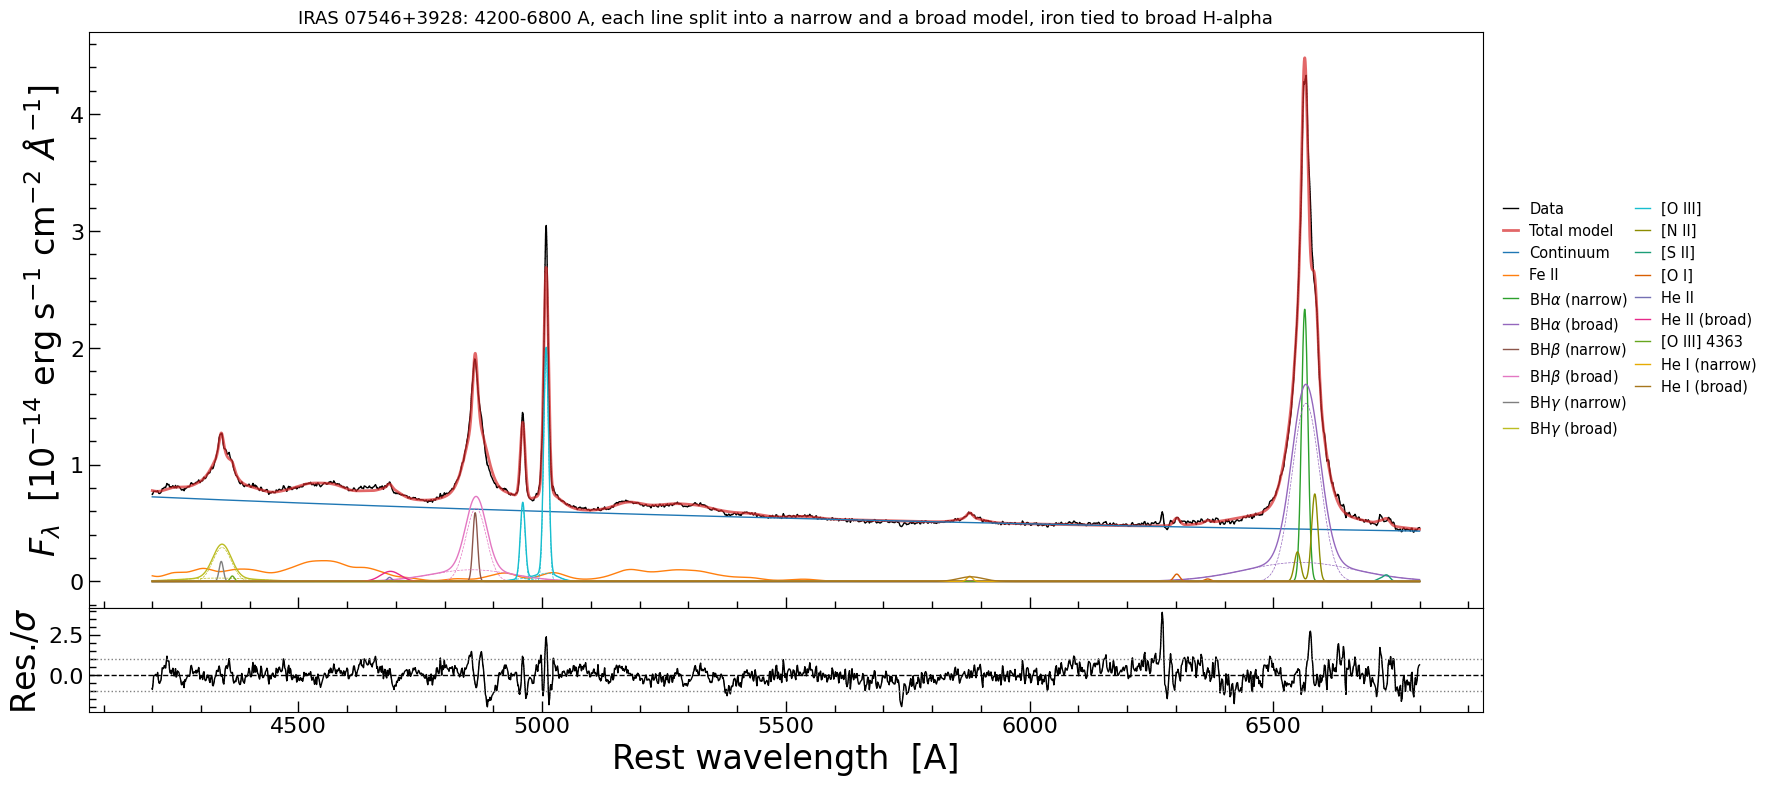

In [17]:
# residual_in_sigma divides by the error, so the panel shows "how many sigma" and
# a single bright pixel can no longer set the scale of the whole panel.
fig = plt.figure(figsize=(17.0, 8.0))
ax = fig.add_axes([0.055, 0.20, 0.82, 0.72])
axr = fig.add_axes([0.055, 0.07, 0.82, 0.13])
galspec.plot.plot_fit(
    wave, flux, model_cpu, ax=ax, axr=axr, mask_list=MASK_WINDOWS,
    error=error, residual_in_sigma=True,
    xlabel="Rest wavelength  [A]",
    ylabel=r"$F_\lambda$  [$10^{-14}$ erg s$^{-1}$ cm$^{-2}$ $\AA^{-1}$]",
    legend_kwargs={"fontsize": 10.5, "ncol": 2, "loc": "center left",
                   "bbox_to_anchor": (1.005, 0.5), "frameon": False})
ax.set_title("IRAS 07546+3928: 4200-6800 A, each line split into a narrow and a "
             "broad model, iron tied to broad H-alpha", fontsize=13)


### Zooms

The whole-spectrum figure is crowded; the same function, called on a wavelength
window, shows the components where they matter.


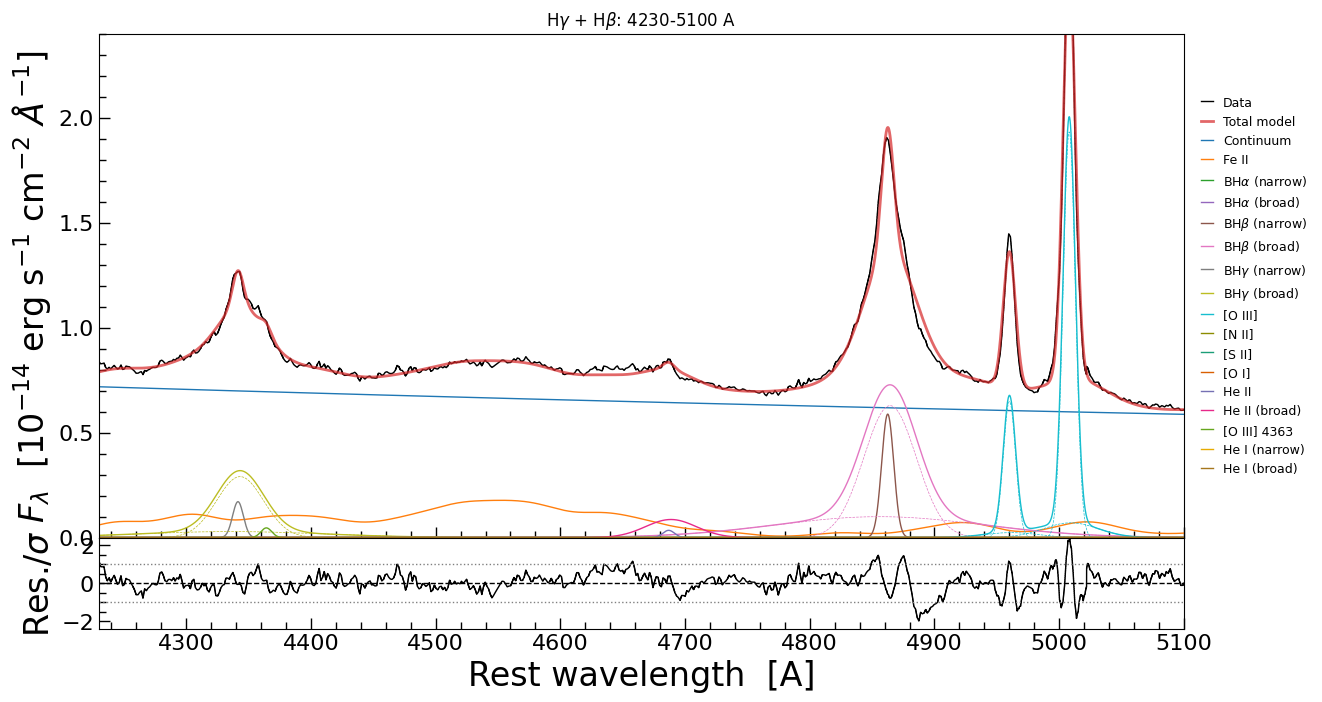

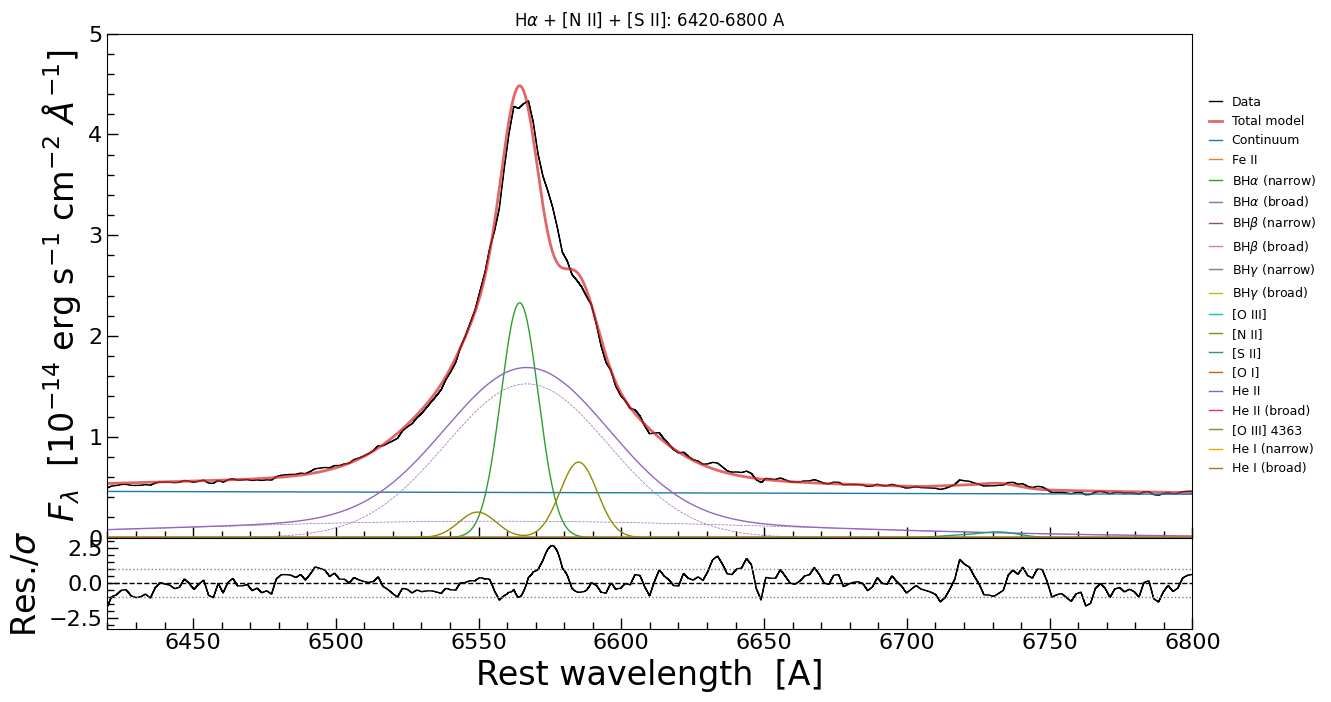

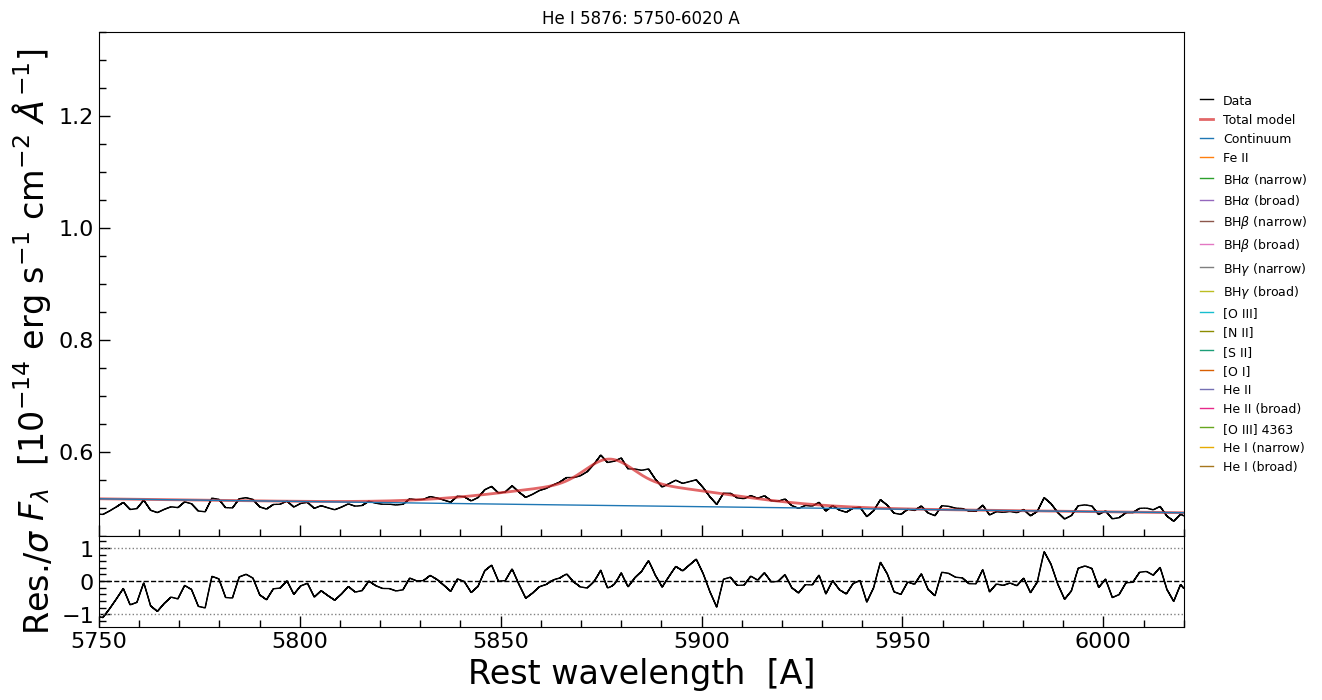

In [18]:
zooms = [("H$\\gamma$ + H$\\beta$", (4230, 5100), (0.0, 2.4)),
         ("H$\\alpha$ + [N II] + [S II]", (6420, 6800), (0.0, 5.0)),
         ("He I 5876", (5750, 6020), (0.45, 1.35))]


def residual_limits(wave, flux, error, model, xlim):
    """Residual limits for one panel, in sigma, from that panel's own scatter."""
    inside = (wave >= xlim[0]) & (wave <= xlim[1])
    residual = ((flux - np.asarray(model(wave))) / error)[inside]
    scale = float(np.nanpercentile(np.abs(residual), 99.5))
    return (-1.25 * scale - 0.06, 1.25 * scale + 0.06)


for title, xlim, ylim in zooms:
    fig = plt.figure(figsize=(15.5, 7.0))
    ax = fig.add_axes([0.06, 0.20, 0.70, 0.72])
    axr = fig.add_axes([0.06, 0.07, 0.70, 0.13])
    # The legend sits outside the axes: drawn inside, an opaque frame covered the
    # [O II] 3727 peak in the blue-end panel -- the one feature that panel exists
    # to show.
    galspec.plot.plot_fit(
        wave, flux, model_cpu, ax=ax, axr=axr, xlim=xlim, ylim0=ylim,
        ylim1=residual_limits(wave, flux, error, model_cpu, xlim),
        mask_list=MASK_WINDOWS, error=error, residual_in_sigma=True,
        xlabel="Rest wavelength  [A]",
        ylabel=r"$F_\lambda$  [$10^{-14}$ erg s$^{-1}$ cm$^{-2}$ $\AA^{-1}$]",
        legend_kwargs={"fontsize": 9.0, "ncol": 1, "loc": "center left",
                       "bbox_to_anchor": (1.005, 0.5), "frameon": False})
    ax.set_title(f"{title}: {xlim[0]:.0f}-{xlim[1]:.0f} A", fontsize=12)
    plt.show()


### Correlations

Nested sampling gives the full posterior, not just error bars. An elongated blob
means two parameters trade off against each other -- a broader component with a
smaller peak, say -- and quoting them independently would be misleading.


### Marginal posteriors

The corner plot shows every pair; for the numbers people actually quote, one
histogram each is easier to read. `plot_posterior_hist` draws the marginal
posterior, marks the median and the 16-84 band, and prints the value on top.

The **x range comes from the posterior, not from the prior**. That matters: the
prior on a width spans 300-8000 km/s while the posterior spans a few km/s, so an
axis stretched to the prior would draw the measurement as a spike one pixel wide
and hide the shape that the panel exists to show. A parameter that has genuinely
filled its prior still looks flat, because the histogram itself is flat -- and
when a prior bound falls outside the plotted range its value is written in the
corner, so nothing is hidden by the zoom.


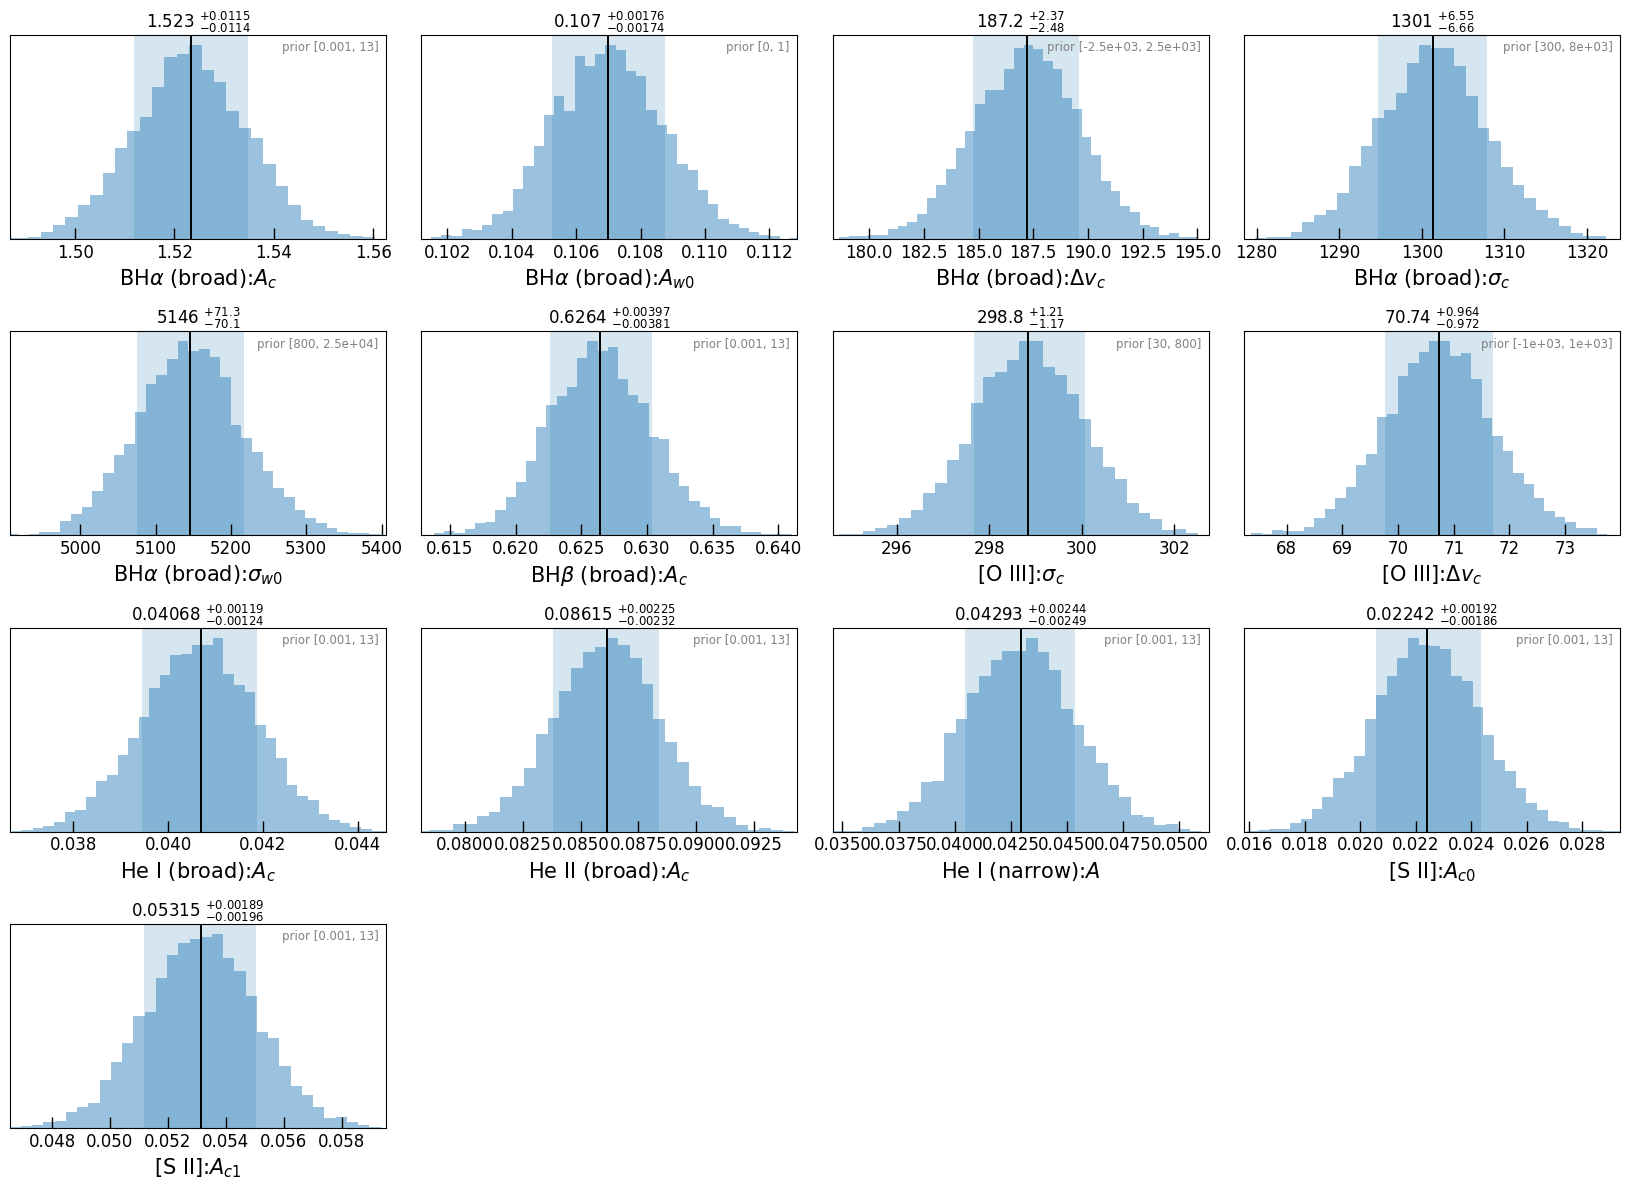

In [19]:
# Most of the time the marginals are all that is wanted, and a corner plot of thirty
# parameters is unreadable.  Each panel shows the histogram, the median and the 16-84
# percentile band, with the value printed on top.  The x range comes from the
# posterior, not from the prior: if it came from the prior, a parameter measured to
# 0.5% would be drawn as a spike one pixel wide.  When a prior bound is off the
# plotted range it is written in the corner instead of stretching the axis.
quoted = ["b_halpha.amp_c", "b_halpha.amp_w0", "b_halpha.dv_c", "b_halpha.sigma_c",
          "b_halpha.sigma_w0", "b_hbeta.amp_c", "OIII.sigma_c", "OIII.dv_c",
          "b_hei.amp_c", "b_heii.amp_c", "n_hei.amplitude",
          "SII.amp_c0", "SII.amp_c1"]
fig, axes = galspec.plot.plot_posterior_hist(
    fit, params=[q for q in quoted if q in fit.full_param_names], ncols=4, bins=40)
plt.show()


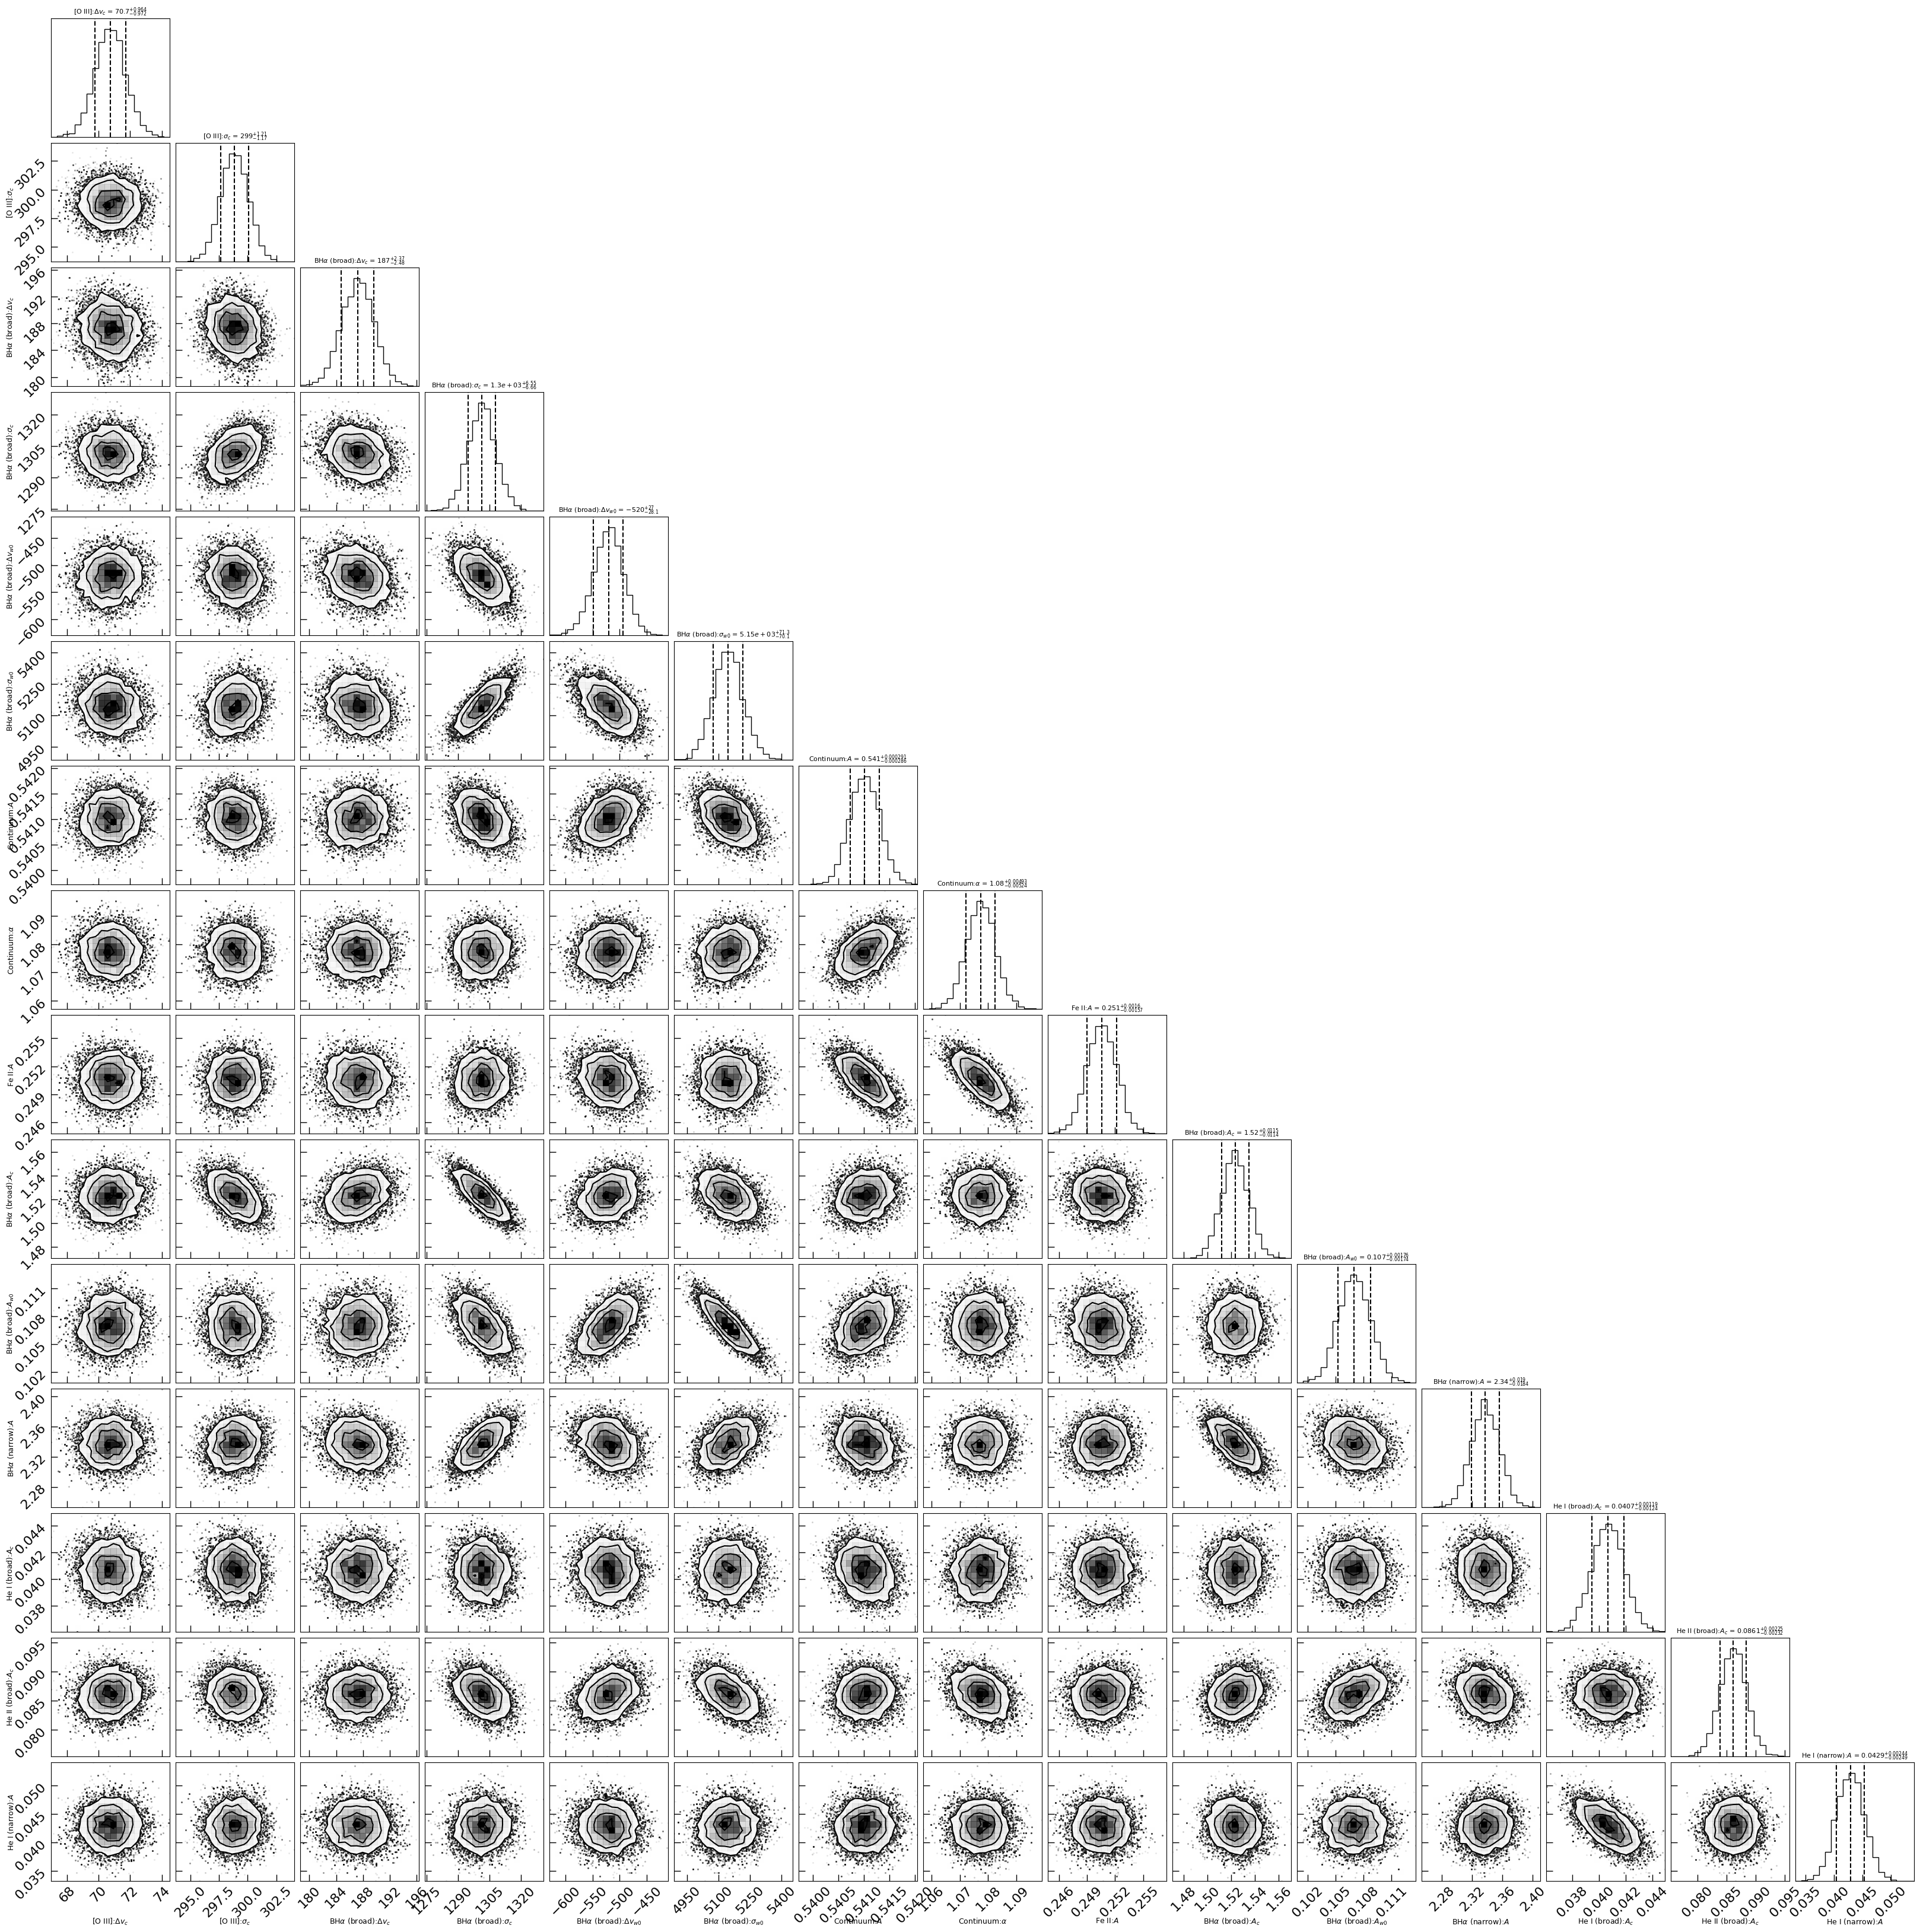

In [20]:
import corner

wanted = ["OIII.dv_c", "OIII.sigma_c", "b_halpha.dv_c", "b_halpha.sigma_c",
          "b_halpha.dv_w0", "b_halpha.sigma_w0", "Continuum.amplitude", "Continuum.alpha",
          "FeII.amplitude", "b_halpha.amp_c", "b_halpha.amp_w0", "n_halpha.amplitude",
          "b_hei.amp_c", "b_heii.amp_c", "n_hei.amplitude"]
keep = [fit.full_param_names.index(name) for name in wanted
        if name in fit.full_param_names]
# param_labels turns "b_halpha.sigma_w0" into "BH$\alpha$:$\sigma_{w0}$"
fig = corner.corner(fit.samples_equal_weight[:, keep],
                    labels=[fit.param_labels[i] for i in keep],
                    quantiles=(0.16, 0.5, 0.84), show_titles=True, title_fmt=".3g",
                    title_kwargs={"fontsize": 8}, label_kwargs={"fontsize": 9})


## 9. What this does and does not show

* The blue end of the fitted range, 4200-4400 A, is the weakest part of the
  model: H-gamma is cut by the window edge on its blue wing, and there is no
  Balmer continuum, which rises towards its 3646 A limit and is not modelled at
  all. Trust H-gamma's broad flux less than H-alpha's.
* The two broad components are a *description* of a profile, not a physical
  decomposition. Real broad-line profiles have longer wings than any Gaussian, so
  read them as "a broad part and a broader part" and treat their individual
  fluxes as indicative. Because the iron kernel is tied to them, that caveat
  propagates to the iron profile too. They are also *exchangeable* (see the
  priors section), which is why their width ranges are disjoint -- without that,
  "core" and "wind" would be two labels for the same two numbers.
* Without the LSF folded in, the narrow widths include the instrument (~150 km/s
  FWHM, small next to ~700 km/s but not zero). Subtract it in quadrature if you
  need the gas kinematics alone.
* The narrow lines share one width by construction -- the standard assumption for
  forbidden-line regions, but it means a genuinely different narrow kinematics
  per line could not be detected.
* The [S II] ratio is measured, not assumed, because it is a density diagnostic:
  I(6716)/I(6731) near 1.3 means low-density gas, near 0.5 high-density. Turning
  it into an electron density needs a temperature and the atomic data, which is
  beyond a line-profile fit.
* The Fe II *shape* is still a template: tying its kernel to broad H-alpha fixes
  the broadening, but the relative strengths of the iron lines come from the
  reference object (Mrk 493). A real AGN with a different iron excitation would
  need a different template, not a different width.
* He I 5876 is fitted with one broad component; the line is weak, so its broad
  fraction is the least well constrained number in the table.
* The evidence (`log Z`) is only comparable between runs made with the same
  sampler.

## Where to go next

* `python fit_iras07546_jax.py` -- the same fit as a batch script.
* `python fit_iras07546_jax.py --quick` -- a rough answer in a few minutes.
* `docs/source/jax_gpu.rst` -- the CPU/GPU benchmark built on a fit like this.
* `tests/test_jax_parity.py` -- proves the JAX models equal the astropy ones,
  the tied iron included.
* `tests/test_model_features.py` -- pins the iron template's grid and padding, the
  tied kernel, and the other model features this fit relies on.
* `tests/test_jax_io.py` -- proves the FITS round trip gives back the same fit.


## 10. Saving the fit so it can be reused

A nested-sampling run is expensive; the file should be the thing you keep. Two
files are written:

* `output/iras07546_jax_posterior.npz` -- a plain array dump, handy for a quick
  numpy read;
* `output/iras07546_jax_fit.fits` -- everything: the posterior samples, their
  unit-cube coordinates, the evidence and its error, the parameter names, bounds
  and priors, the sampler's convergence trajectory, the model description and the
  spectrum that was fitted.

The FITS layout is the one `galspec.dynesty_fit_io` already uses (`SAMPLES`,
`LOGWT`, `LOGL`, `LOGVOL`, `SAMPLES_EQ`, `PARAM_NAMES`, `PARAM_BOUNDS`,
`MODEL_PARAM`, `MODEL_STR`, ...), with three JNesty-only extensions: `SAMPLES_U`,
`DLZ_TRAJ` and `SCALE_TR`. The model is written by
`galspec.jax_models.serialization`, which records what a JAX model needs and an
astropy model does not -- the number of Gaussians per line, a template name or a
polynomial degree -- and the ties as *references* (`"OIII.dv_c"`), so they are
restored no matter how they were written in the code.


In [21]:
(EXAMPLE_DIR / "output").mkdir(exist_ok=True)
outfile = EXAMPLE_DIR / "output" / "iras07546_jax_posterior.npz"
np.savez_compressed(outfile,
                    samples=fit.samples_equal_weight,
                    parameter_names=np.array(fit.param_names),
                    qualified_names=np.array(fit.full_param_names),
                    log_evidence=fit.log_evidence,
                    log_evidence_error=fit.log_evidence_err,
                    wave=wave, flux=flux, error=error, predicted=predicted)
print(f"wrote {outfile}")

# The FITS file is the complete record of the fit: the samples (and their
# unit-cube coordinates), the evidence, the bounds, the sampler's convergence
# trajectory, the model itself and the data it was made against.
fits_out = EXAMPLE_DIR / "output" / "iras07546_jax_fit.fits"
save_jnesty_fit_to_fits(fit, fits_out)
print(f"wrote {fits_out}  ({fits_out.stat().st_size / 1e6:.1f} MB)")


wrote /home/shangguan/Softwares/my_modules/GalSpec/example/output/iras07546_jax_posterior.npz
JNesty_Fit object saved to /home/shangguan/Softwares/my_modules/GalSpec/example/output/iras07546_jax_fit.fits
wrote /home/shangguan/Softwares/my_modules/GalSpec/example/output/iras07546_jax_fit.fits  (57.0 MB)


### Reading it back

`load_jnesty_fit_from_fits` rebuilds the model and the fit, and every summary and
plot works on the result. The one thing it cannot rebuild is the prior
*transform*: `custom_priors` are Python callables and a closure cannot be written
to a file, so the file stores the resulting bounds and the names that had a
custom prior. A loaded fit is therefore for reading results, not for resuming the
sampler.


In [22]:
# Reading it back gives a JNesty_Fit with the same posterior, evidence, bounds and
# model -- and no sampler. This is the file worth keeping.
loaded = load_jnesty_fit_from_fits(fits_out)

print(f"log Z stored    {fit.log_evidence:12.2f} +/- {fit.log_evidence_err:.2f}")
print(f"log Z reloaded  {loaded.log_evidence:12.2f} +/- {loaded.log_evidence_err:.2f}")
print("same parameters:  ", list(loaded.param_names) == list(fit.param_names))
print("same posterior:   ",
      np.allclose(loaded.samples_equal_weight, fit.samples_equal_weight))

# everything the original object could do, it can do again
quantiles = loaded.get_quantiles((0.16, 0.5, 0.84))
print()
print(f"{'parameter':22s} {'16%':>10s} {'50%':>10s} {'84%':>10s}")
for index, name in enumerate(loaded.full_param_names[:6]):
    lo, mid, hi = quantiles[:, index]
    print(f"{name:22s} {lo:10.4g} {mid:10.4g} {hi:10.4g}")


JNesty_Fit object loaded from /home/shangguan/Softwares/my_modules/GalSpec/example/output/iras07546_jax_fit.fits
log Z stored       130880.55 +/- 0.64
log Z reloaded     130880.55 +/- 0.64
same parameters:   True
same posterior:    True

parameter                     16%        50%        84%
Continuum.amplitude        0.5407      0.541     0.5413
Continuum.alpha             1.072      1.077      1.082
FeII.amplitude              0.249     0.2506     0.2522
n_halpha.amplitude          2.319      2.337      2.356
b_halpha.amp_c              1.512      1.523      1.535
b_halpha.dv_c               184.7      187.2      189.6


### Handing the GPU back

JNesty's device memory is dominated by one buffer that is allocated once at
`max_iterations` size (the dead-point history), plus the live set and the
compiled kernels. It does not grow from iteration to iteration, but an XLA
context never returns its high-water mark to the driver either, so a process that
has finished one fit keeps showing it in `nvidia-smi`. `release_device_buffers()`
drops the sampler and clears JAX's caches; the results, the model and the saved
files are untouched.


In [23]:
# The sampler still holds buffers on the GPU sized by max_iterations, and an XLA
# context never gives its high-water mark back to the driver. Everything so far
# lives in host memory (and in the two files), so hand the card back to other
# jobs; the results stay usable.
fit.release_device_buffers()
print("sampler released; quantiles still available:", fit.get_quantiles().shape)


sampler released; quantiles still available: (3, 30)
